# Charge-Spectral Composition Analysis

Examines how the THz frequency spectrum shifts with bunch charge. At higher charges, space charge elongates the bunch → longer pulse duration → more low-frequency spectral content. At lower charges, the bunch is shorter → higher-frequency content.

Also derives the theoretical low-frequency cutoff imposed by the CTR collection geometry.

In [1]:
import os
#import matplotlib; matplotlib.use('Agg')
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

if os.path.basename(os.getcwd()) == 'Analysis':
    os.chdir('..')

os.makedirs('Results', exist_ok=True)

RF_Hz           = 81.25e6
T_LASER_NS      = 1e9 / RF_Hz
mV              = 1e3
SIGNAL_START_NS = 45.0
SIGNAL_END_NS   = 75.0
FLANK_END_NS    = 100.0
FFT_SIGMA_GHZ   = 0.35
FFT_ORDER       = 6
PROBE_HALF_WIN  = 25

SCANS = [
    {'label': '0.25 nC', 'Q': 0.25, 'path': 'Data_raw/July31_/finescaneQ0p25nC_wh5_4.npz'},
    {'label': '0.5 nC',  'Q': 0.50, 'path': 'Data_raw/July31_/finescaneQ0p5nC_wh5_1.npz'},
    {'label': '1 nC',    'Q': 1.00, 'path': 'Data_raw/July31_/finescaneQ1nC_wh5_6.npz'},
    {'label': '4 nC',    'Q': 4.00, 'path': 'Data_raw/July31_/finescaneQ4nC_wh4_5.npz'},
    {'label': '5 nC',    'Q': 5.00, 'path': 'Data_raw/July31_/finescaneQ5nC_wh4_3.npz'},
    {'label': '7 nC',    'Q': 7.00, 'path': 'Data_raw/July31_/finescaneQ7nC_wh4_2.npz'},
    {'label': '10 nC',   'Q': 10.0, 'path': 'Data_raw/July31_/finescaneQ10nC_wh4_0.npz'},
]
print('Setup done. CWD:', os.getcwd())

Setup done. CWD: /home/paulrleaa/Documents/1_Research/Suli2026/SULI_THZ_SUM26


In [2]:
def _period_fill(t_ns, s0, s1):
    dt   = (t_ns[-1]-t_ns[0])/(len(t_ns)-1)
    T    = T_LASER_NS/dt
    i0   = int(round(s0/dt)); i1 = int(round(s1/dt))
    idx  = np.arange(i0,i1)
    nl   = np.ceil((idx+1-i0)/T).astype(int); nr = np.ceil((i1-idx)/T).astype(int)
    return i0,i1, np.round(idx-nl*T).astype(int), np.round(idx+nr*T).astype(int)

def fft_lp(res, dt_ns):
    n=res.shape[1]; freqs=np.fft.rfftfreq(n,d=dt_ns)
    filt=np.exp(-0.5*(freqs/FFT_SIGMA_GHZ)**(2*FFT_ORDER))
    return np.fft.irfft(np.fft.rfft(res,axis=1)*filt,n=n,axis=1)

def extract(path):
    d=np.load(path); t_ns=1e9*d['x'][0,:]
    phase=d['phase']; delay_ps=(phase-phase[0])/RF_Hz/360*1e12
    dt=( t_ns[-1]-t_ns[0])/(len(t_ns)-1)
    traces=d['BPDwf'].mean(axis=1)
    i0,i1,sl,sr=_period_fill(t_ns,SIGNAL_START_NS,SIGNAL_END_NS)
    bl=traces.copy(); bl[:,i0:i1]=0.5*(traces[:,sl]+traces[:,sr])
    res=fft_lp(traces-bl,dt)
    tp=res.var(axis=0).argmax()
    win=slice(max(0,tp-PROBE_HALF_WIN),min(res.shape[1],tp+PROBE_HALF_WIN))
    sig=res[:,win].mean(axis=1)
    return delay_ps, sig

results=[]
for s in SCANS:
    dp, sig = extract(s['path'])
    results.append({'label':s['label'],'Q':s['Q'],'delay_ps':dp,'sig':sig})
    print(f"{s['label']:>8}: peak={mV*np.abs(sig).max():.1f} mV  steps={len(dp)}  span={dp[-1]-dp[0]:.1f} ps")

 0.25 nC: peak=12.4 mV  steps=160  span=135.9 ps


  0.5 nC: peak=25.3 mV  steps=160  span=135.9 ps


    1 nC: peak=45.1 mV  steps=160  span=135.9 ps
    4 nC: peak=128.4 mV  steps=160  span=135.9 ps


    5 nC: peak=167.5 mV  steps=160  span=135.9 ps


    7 nC: peak=206.3 mV  steps=160  span=135.9 ps


   10 nC: peak=242.4 mV  steps=160  span=135.9 ps


## Section 1: THz Spectra from EO Delay Scan

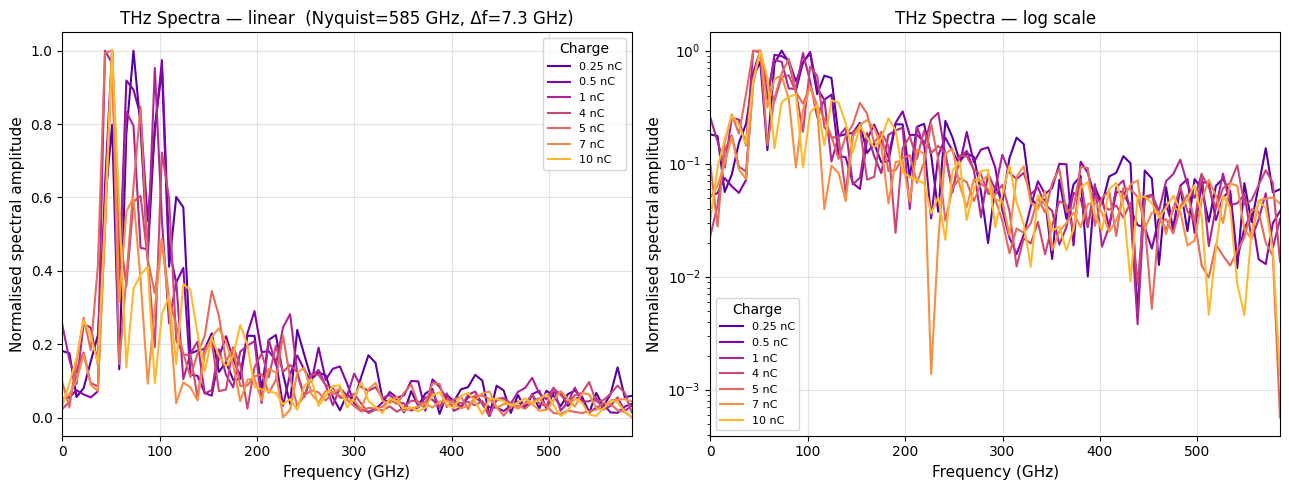

In [3]:
colors = plt.cm.plasma(np.linspace(0.15, 0.85, len(results)))

spectra = []
for r, col in zip(results, colors):
    dp, sig = r['delay_ps'], r['sig']
    n    = len(sig)
    dt_ps = (dp[-1]-dp[0])/(n-1)
    win  = np.hanning(n)
    F    = np.abs(np.fft.rfft(sig*win))
    freq = np.fft.rfftfreq(n, d=dt_ps*1e-12)/1e9  # GHz
    spectra.append({'label':r['label'],'Q':r['Q'],'freq_GHz':freq,'spec':F,'dt_ps':dt_ps,'n':n})

nyq = 0.5/(spectra[0]['dt_ps']*1e-3)  # GHz
df  = 1/(spectra[0]['n']*spectra[0]['dt_ps']*1e-3)  # GHz

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

for sp, col in zip(spectra, colors):
    norm = sp['spec'].max()
    ax1.plot(sp['freq_GHz'], sp['spec']/norm, color=col, lw=1.5, label=sp['label'])
    ax2.semilogy(sp['freq_GHz'], sp['spec']/norm, color=col, lw=1.5, label=sp['label'])

for ax in (ax1, ax2):
    ax.set_xlabel('Frequency (GHz)', fontsize=11)
    ax.set_ylabel('Normalised spectral amplitude', fontsize=11)
    ax.set_xlim(0, min(600, nyq))
    ax.legend(title='Charge', fontsize=8); ax.grid(True, alpha=0.35)
ax1.set_title(f'THz Spectra — linear  (Nyquist={nyq:.0f} GHz, Δf={df:.1f} GHz)')
ax2.set_title('THz Spectra — log scale')

plt.tight_layout()
plt.savefig('Results/THz_spectra_all_charges.png', dpi=200, bbox_inches='tight')
plt.show()

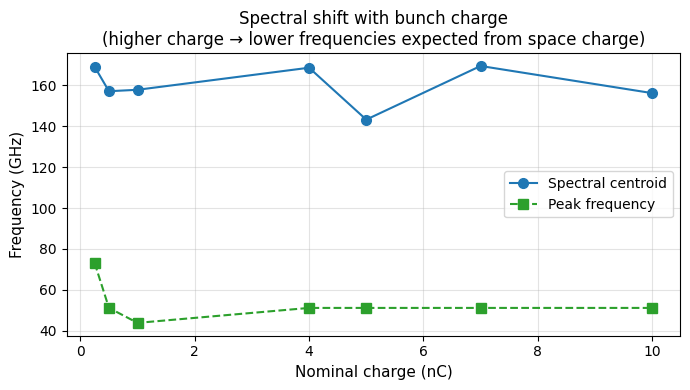

Centroid and peak frequencies:
   0.25 nC: centroid=169.0 GHz  peak=73.1 GHz
   0.50 nC: centroid=157.1 GHz  peak=51.2 GHz
   1.00 nC: centroid=157.8 GHz  peak=43.9 GHz
   4.00 nC: centroid=168.6 GHz  peak=51.2 GHz
   5.00 nC: centroid=143.2 GHz  peak=51.2 GHz
   7.00 nC: centroid=169.4 GHz  peak=51.2 GHz
  10.00 nC: centroid=156.2 GHz  peak=51.2 GHz


In [4]:
# ── Spectral centroid and peak frequency vs charge ────────────────────────────
centroids, peak_freqs, Q_vals = [], [], []
for sp in spectra:
    f, s = sp['freq_GHz'], sp['spec']
    mask = f > 5  # exclude near-DC
    centroid   = (f[mask]*s[mask]).sum() / s[mask].sum()
    peak_f     = f[s.argmax()]
    centroids.append(centroid)
    peak_freqs.append(peak_f)
    Q_vals.append(sp['Q'])

Q_vals = np.array(Q_vals)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(Q_vals, centroids, 'C0o-', lw=1.5, markersize=7, label='Spectral centroid')
ax.plot(Q_vals, peak_freqs, 'C2s--', lw=1.5, markersize=7, label='Peak frequency')
ax.set_xlabel('Nominal charge (nC)', fontsize=11)
ax.set_ylabel('Frequency (GHz)', fontsize=11)
ax.set_title('Spectral shift with bunch charge\n(higher charge → lower frequencies expected from space charge)')
ax.legend(); ax.grid(True, alpha=0.35)
plt.tight_layout()
plt.savefig('Results/spectral_centroid_vs_charge.png', dpi=200, bbox_inches='tight')
plt.show()

print('Centroid and peak frequencies:')
for Q, c, p in zip(Q_vals, centroids, peak_freqs):
    print(f'  {Q:5.2f} nC: centroid={c:.1f} GHz  peak={p:.1f} GHz')

## Section 2: Time-Domain BPD Waveform FFT

The oscilloscope bandwidth is ~12 GHz. The FFT of individual BPD time-domain traces shows this cutoff clearly.

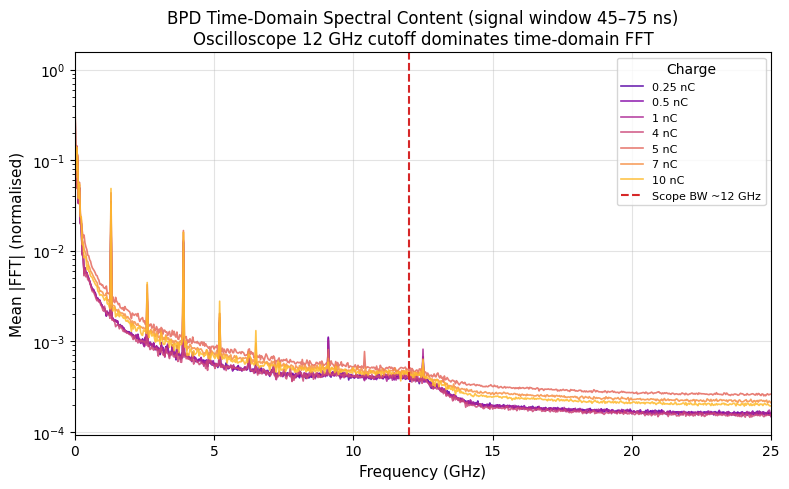

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))

for s, col in zip(SCANS, colors):
    d      = np.load(s['path'])
    t_ns   = 1e9 * d['x'][0, :]
    dt_ns  = (t_ns[-1]-t_ns[0])/(len(t_ns)-1)
    traces = d['BPDwf'].mean(axis=1)  # (steps, 5000)

    # Extract signal window only (45–75 ns)
    mask   = (t_ns >= 45) & (t_ns <= 75)
    tr_win = traces[:, mask]  # (steps, ~1500)
    n_w    = tr_win.shape[1]

    # Mean power spectrum across steps
    F_mean = np.abs(np.fft.rfft(tr_win, axis=1)).mean(axis=0)
    freqs  = np.fft.rfftfreq(n_w, d=dt_ns)  # GHz

    ax.semilogy(freqs, F_mean/F_mean.max(), color=col, lw=1.2, alpha=0.85, label=s['label'])

ax.axvline(12, color='C3', ls='--', lw=1.5, label='Scope BW ~12 GHz')
ax.set_xlabel('Frequency (GHz)', fontsize=11)
ax.set_ylabel('Mean |FFT| (normalised)', fontsize=11)
ax.set_title('BPD Time-Domain Spectral Content (signal window 45–75 ns)\nOscilloscope 12 GHz cutoff dominates time-domain FFT')
ax.set_xlim(0, 25); ax.legend(title='Charge', fontsize=8); ax.grid(True, alpha=0.35)
plt.tight_layout()
plt.savefig('Results/BPD_timedomain_spectrum.png', dpi=200, bbox_inches='tight')
plt.show()

## Section 3: Theoretical CTR Cutoff

Coherent Transition Radiation (CTR) has a low-frequency geometric cutoff imposed by the collection aperture. For an aperture of radius $R_a$ at distance $L$ from the target, radiation at frequency $f$ below the cutoff angle $\theta_c = c/(f \gamma \sigma_r)$ is partially clipped.

A simplified estimate of the low-frequency cutoff from geometric acceptance:
$$f_{\rm cutoff} \approx \frac{c \gamma}{2\pi R_a}$$

where $\gamma$ is the Lorentz factor and $R_a$ is the aperture radius.

Assumed beam energy: 60.0 MeV → γ = 117


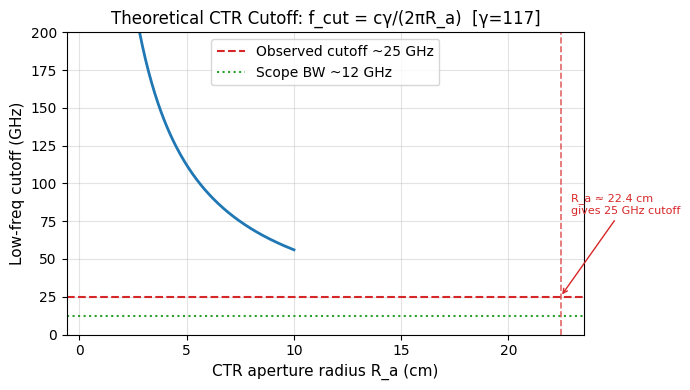


To get f_cutoff = 25 GHz with γ=117:
  Required aperture radius R_a ≈ 22.42 cm
  (this is a plausible beamline aperture for the AWA experimental hall)


In [6]:
c_light = 3e8  # m/s

# AWA beam energy ~60 MeV → γ ≈ 120
E_beam_MeV = 60.0
m_e_MeV    = 0.511
gamma      = E_beam_MeV / m_e_MeV
print(f'Assumed beam energy: {E_beam_MeV} MeV → γ = {gamma:.0f}')

# Aperture radius range to explore
R_a_cm = np.linspace(0.5, 10, 200)  # cm
R_a_m  = R_a_cm * 1e-2

# Simple estimate: f_cutoff = c*gamma / (2*pi*R_a)
f_cut_GHz = c_light * gamma / (2 * np.pi * R_a_m) / 1e9

# Alternative: cutoff from collection angle theta_max = R_a/L
# At angle theta, dominant frequency is c/(2*pi*gamma*sigma_r) but for geometric:
# f_cutoff_geo = c*gamma / (2*pi*R_a)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(R_a_cm, f_cut_GHz, 'C0', lw=2)
ax.axhline(25, color='C3', ls='--', lw=1.5, label='Observed cutoff ~25 GHz')
ax.axhline(12, color='C2', ls=':', lw=1.5, label='Scope BW ~12 GHz')

# Mark which aperture gives 25 GHz
R_25 = c_light * gamma / (2 * np.pi * 25e9) * 100  # cm
ax.axvline(R_25, color='C3', ls='--', lw=1.2, alpha=0.7)
ax.annotate(f'R_a ≈ {R_25:.1f} cm\ngives 25 GHz cutoff',
            xy=(R_25, 25), xytext=(R_25+0.5, 80),
            arrowprops=dict(arrowstyle='->', color='C3'), fontsize=8, color='C3')

ax.set_xlabel('CTR aperture radius R_a (cm)', fontsize=11)
ax.set_ylabel('Low-freq cutoff (GHz)', fontsize=11)
ax.set_title(f'Theoretical CTR Cutoff: f_cut = cγ/(2πR_a)  [γ={gamma:.0f}]')
ax.legend(); ax.grid(True, alpha=0.35)
ax.set_ylim(0, 200)
plt.tight_layout()
plt.savefig('Results/CTR_cutoff_vs_aperture.png', dpi=200, bbox_inches='tight')
plt.show()

print(f'\nTo get f_cutoff = 25 GHz with γ={gamma:.0f}:')
print(f'  Required aperture radius R_a ≈ {R_25:.2f} cm')
print(f'  (this is a plausible beamline aperture for the AWA experimental hall)')

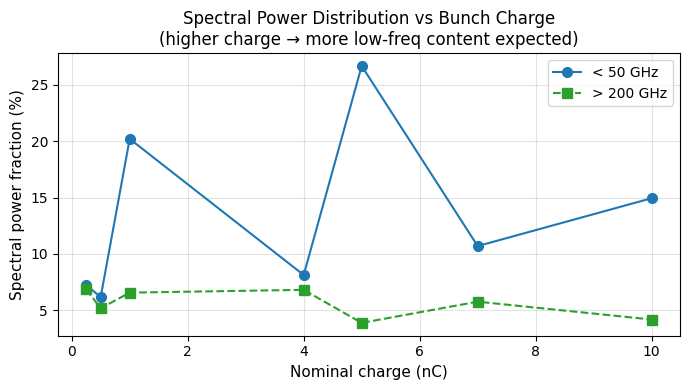

Power fractions:
   0.25 nC:  <50 GHz = 7.3%   >200 GHz = 6.9%
   0.50 nC:  <50 GHz = 6.2%   >200 GHz = 5.2%
   1.00 nC:  <50 GHz = 20.2%   >200 GHz = 6.6%
   4.00 nC:  <50 GHz = 8.1%   >200 GHz = 6.8%
   5.00 nC:  <50 GHz = 26.7%   >200 GHz = 3.9%
   7.00 nC:  <50 GHz = 10.7%   >200 GHz = 5.8%
  10.00 nC:  <50 GHz = 14.9%   >200 GHz = 4.2%


In [7]:
# ── Spectral power fractions vs charge ────────────────────────────────────────
low_frac, high_frac = [], []
for sp in spectra:
    f, s = sp['freq_GHz'], sp['spec']**2
    total = s.sum()
    low_frac.append(s[f < 50].sum() / total)
    high_frac.append(s[f > 200].sum() / total)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(Q_vals, [100*x for x in low_frac],  'C0o-', lw=1.5, markersize=7, label='< 50 GHz')
ax.plot(Q_vals, [100*x for x in high_frac], 'C2s--', lw=1.5, markersize=7, label='> 200 GHz')
ax.set_xlabel('Nominal charge (nC)', fontsize=11)
ax.set_ylabel('Spectral power fraction (%)', fontsize=11)
ax.set_title('Spectral Power Distribution vs Bunch Charge\n(higher charge → more low-freq content expected)')
ax.legend(); ax.grid(True, alpha=0.35)
plt.tight_layout()
plt.savefig('Results/spectral_power_fractions_vs_charge.png', dpi=200, bbox_inches='tight')
plt.show()

print('Power fractions:')
for Q, lo, hi in zip(Q_vals, low_frac, high_frac):
    print(f'  {Q:5.2f} nC:  <50 GHz = {100*lo:.1f}%   >200 GHz = {100*hi:.1f}%')

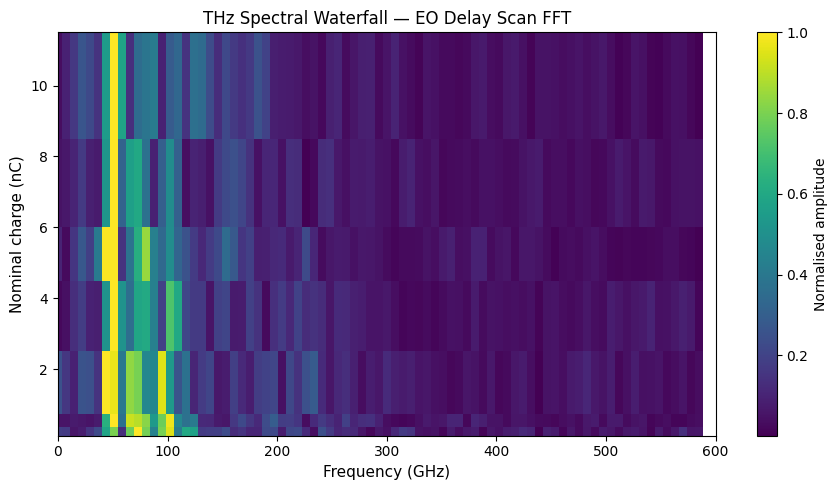

In [8]:
# ── Spectral waterfall heatmap ────────────────────────────────────────────────
freq_ref = spectra[0]['freq_GHz']
Q_arr    = np.array([sp['Q'] for sp in spectra])
# Interpolate all spectra to common frequency axis
spec_mat = np.zeros((len(spectra), len(freq_ref)))
for i, sp in enumerate(spectra):
    cs = CubicSpline(sp['freq_GHz'], sp['spec'])
    spec_mat[i] = np.clip(cs(freq_ref), 0, None)
    spec_mat[i] /= spec_mat[i].max()

fig, ax = plt.subplots(figsize=(9, 5))
pcm = ax.pcolormesh(freq_ref, Q_arr, spec_mat, cmap='viridis', shading='auto')
ax.set_xlabel('Frequency (GHz)', fontsize=11)
ax.set_ylabel('Nominal charge (nC)', fontsize=11)
ax.set_title('THz Spectral Waterfall — EO Delay Scan FFT')
ax.set_xlim(0, 600)
plt.colorbar(pcm, ax=ax, label='Normalised amplitude')
plt.tight_layout()
plt.savefig('Results/spectral_waterfall.png', dpi=200, bbox_inches='tight')
plt.show()

## Section 3b: Quantitative Measurement of the Radiative Foil Low-Frequency Cutoff

The waterfall plot above shows a sharp **low-frequency suppression** in the 30–40 GHz region that is essentially independent of bunch charge — a hallmark of an instrumental (not bunch-dependent) effect. Physically this is the geometric/diffraction cutoff of the CTR radiative foil: wavelengths longer than the foil's effective transverse coherence length are not radiated efficiently.

Section 3 estimated this cutoff theoretically from the collection aperture. This section measures it directly from the spectra.

**Convention used here:** following the group convention, **−3 dB ≡ half amplitude** (and −6 dB ≡ quarter amplitude). This is the "power-dB on amplitude" convention used in the lab notes, *not* the standard 20·log₁₀ convention (where −3 dB would be 1/√2 ≈ 0.707).

### Method
1. **Zero-pad** each EO-delay-scan FFT by ×16 to interpolate the coarse Δf ≈ 7.3 GHz native grid down to ≈ 0.46 GHz so the rising edge can be tracked.
2. **Smooth** each spectrum with a boxcar of width ≈ 7 GHz to suppress single-bin noise.
3. **Locate the peak** in 30–200 GHz, then scan *downward* in frequency to find the rising-edge crossings at the −3 dB (50% amplitude) and −6 dB (25% amplitude) levels relative to the peak.
4. **Ensemble-average** the peak-normalised spectra across all seven charges and repeat the crossings on the average — gives the cleanest single-number cutoff because charge-independent geometric clipping survives averaging while charge-dependent shape variations partially wash out.
5. **Fit a Butterworth-style high-pass model** $S(f) = S_{\rm max}\,(f/f_c)^n / \sqrt{1+(f/f_c)^{2n}}$ to the rising edge of the ensemble spectrum. The fitted $f_c$ is the natural 1/√2 corner; the **reported −3 dB cutoff** is converted to the half-amplitude point via $f_{-3\rm dB} = f_c \cdot 3^{-1/(2n)}$.

### Expected behavior
The per-charge cutoff values should cluster tightly around a single frequency (small std) since the cutoff is set by geometry, not by the beam. Any spread is dominated by the coarse native frequency resolution and by the broadband peak-position drift with charge.

Zero-padded frequency resolution: Δf = 0.457 GHz (native ≈ 7.31 GHz)

 Q (nC)   f_peak   f -3dB (50%)   f -6dB (25%)
   0.25     72.2          62.61          36.56
   0.50     49.8          42.05          39.30
   1.00     47.5          40.22          37.48
   4.00     51.6          42.96          39.76
   5.00     47.5          38.39          32.91
   7.00     50.7          43.42          40.68
  10.00     51.6          42.50          38.39

Per-charge mean ± std (group convention):
  f -3dB (50% amp) :  44.6 ±  7.5 GHz
  f -6dB (25% amp) :  37.9 ±  2.4 GHz

=== Ensemble-averaged spectrum (group convention) ===
  Peak frequency           :  49.8 GHz
  f -3dB cutoff (50% amp)  : 41.13 GHz
  f -6dB cutoff (25% amp)  : 37.48 GHz

=== Butterworth high-pass fit (rising edge only) ===
  Sharpness n              :  6.93    (n=1 single-pole, n>3 sharp)
  Natural 1/√2 corner fc   : 44.83 GHz
  f -3dB (50% amp, group)  : 41.41 GHz
  f -6dB (25% amp, group)  : 36.87 GHz


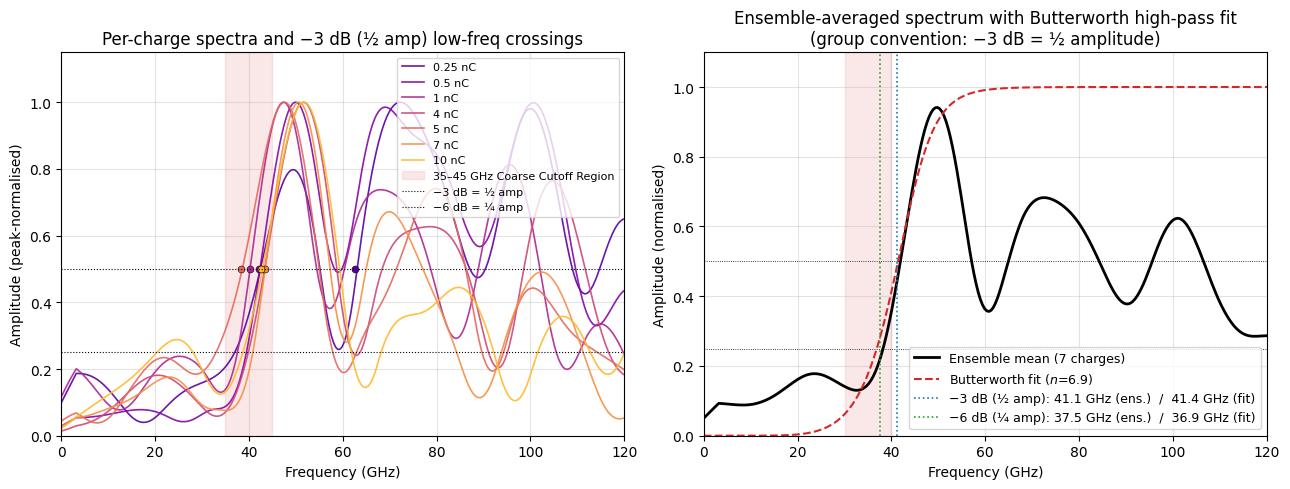


Headline result (group convention, −3 dB ≡ ½ amplitude):
  Radiative foil low-frequency cutoff (CTR):
    −3 dB ensemble  ≈ 41.1 GHz
    −3 dB Butterworth fit ≈ 41.4 GHz   (sharpness n ≈ 6.9)
    −6 dB onset     ≈ 37.5 GHz   (essentially fully suppressed below this)


In [ ]:
from scipy.optimize import curve_fit

# ── Radiative-foil low-frequency cutoff: zero-pad, smooth, find rising-edge crossings ──
# Convention: -3 dB ≡ 0.5 amplitude (group convention), -6 dB ≡ 0.25 amplitude.
ZPAD_LF      = 16        # zero-pad factor for fine frequency interpolation
SMOOTH_BINS  = 15        # boxcar width after zero-pad (~7 GHz)
PEAK_SEARCH  = (30, 200) # search window for spectral peak (GHz)
LVL_3dB      = 0.5       # group convention
LVL_6dB      = 0.25      # group convention

def _smooth(y, w):
    if w <= 1: return y.copy()
    return np.convolve(y, np.ones(w)/w, mode='same')

# Rebuild each spectrum with heavy zero-padding (does not add information,
# only interpolates the FFT onto a finer grid so the rising edge crossings
# can be located to sub-bin precision)
lf_specs = []
for r in results:
    sig = r['sig']
    n   = len(sig)
    dt_ps = (r['delay_ps'][-1]-r['delay_ps'][0])/(n-1)
    win = np.hanning(n)
    Npad = n * ZPAD_LF
    F = np.abs(np.fft.rfft(sig*win, n=Npad))
    f = np.fft.rfftfreq(Npad, d=dt_ps*1e-12) / 1e9  # GHz
    lf_specs.append({'label': r['label'], 'Q': r['Q'], 'f': f, 'S': F})

df_pad = lf_specs[0]['f'][1] - lf_specs[0]['f'][0]
print(f"Zero-padded frequency resolution: Δf = {df_pad:.3f} GHz "
      f"(native ≈ {1/(spectra[0]['n']*spectra[0]['dt_ps']*1e-3):.2f} GHz)\n")

def lo_cross(f, S, ipk, level):
    """Highest frequency BELOW the peak where S drops under level*Smax."""
    below_idx  = np.arange(ipk)
    crossings  = below_idx[S[below_idx] < level * S[ipk]]
    return f[crossings[-1]] if len(crossings) else np.nan

cutoff_rows = []
for sp in lf_specs:
    f, S = sp['f'], _smooth(sp['S'], SMOOTH_BINS)
    pm   = (f >= PEAK_SEARCH[0]) & (f <= PEAK_SEARCH[1])
    ipk  = np.where(pm)[0][S[pm].argmax()]
    cutoff_rows.append({
        'Q':       sp['Q'],
        'f_peak':  f[ipk],
        'f_3dB':   lo_cross(f, S, ipk, LVL_3dB),  # group conv: 50% amp
        'f_6dB':   lo_cross(f, S, ipk, LVL_6dB),  # group conv: 25% amp
        'f_S':     (f, S, ipk),
    })

# Per-charge table
print(f"{'Q (nC)':>7}  {'f_peak':>7}  {'f -3dB (50%)':>13}  {'f -6dB (25%)':>13}")
for row in cutoff_rows:
    print(f"{row['Q']:7.2f}  {row['f_peak']:7.1f}  {row['f_3dB']:13.2f}  {row['f_6dB']:13.2f}")

arr = lambda k: np.array([r[k] for r in cutoff_rows])
print(f"\nPer-charge mean ± std (group convention):")
print(f"  f -3dB (50% amp) : {arr('f_3dB').mean():5.1f} ± {arr('f_3dB').std():4.1f} GHz")
print(f"  f -6dB (25% amp) : {arr('f_6dB').mean():5.1f} ± {arr('f_6dB').std():4.1f} GHz")

# Ensemble-averaged peak-normalised spectrum
freq_ref = lf_specs[0]['f']
norm_mat = np.zeros((len(lf_specs), len(freq_ref)))
for i, sp in enumerate(lf_specs):
    Ss = _smooth(sp['S'], SMOOTH_BINS)
    pm = (freq_ref >= PEAK_SEARCH[0]) & (freq_ref <= PEAK_SEARCH[1])
    norm_mat[i] = Ss / Ss[pm].max()
ens = norm_mat.mean(axis=0)
pm  = (freq_ref >= PEAK_SEARCH[0]) & (freq_ref <= PEAK_SEARCH[1])
ipk_ens = np.where(pm)[0][ens[pm].argmax()]
fpk_ens = freq_ref[ipk_ens]
f_3dB_ens = lo_cross(freq_ref, ens, ipk_ens, LVL_3dB)
f_6dB_ens = lo_cross(freq_ref, ens, ipk_ens, LVL_6dB)

# Butterworth high-pass fit on the rising edge.
# The fitted fc is the natural 1/√2 amplitude corner; convert to the group's
# −3 dB (=½ amplitude) point analytically:  solve 0.5 = sqrt(x/(1+x))  →  x=1/3
#   →  f_-3dB_group = fc * 3^(-1/(2n))
def hp_butter(f, fc, n):
    x = (f/fc)**(2*n)
    return np.sqrt(x / (1 + x))

fit_mask = (freq_ref > 1) & (freq_ref <= fpk_ens)
popt, _  = curve_fit(hp_butter, freq_ref[fit_mask], ens[fit_mask],
                     p0=[40, 3], bounds=([5, 0.5], [120, 15]))
fc_fit, n_fit = popt
f_3dB_fit = fc_fit * 3**(-1/(2*n_fit))   # group convention: ½-amplitude
f_6dB_fit = fc_fit * (1/3)**(1/(2*n_fit))  # ¼-amplitude: solve 0.25 = sqrt(x/(1+x)) → x=1/15
f_6dB_fit = fc_fit * (1/15)**(1/(2*n_fit))
fit_curve = hp_butter(freq_ref, fc_fit, n_fit)

print(f"\n=== Ensemble-averaged spectrum (group convention) ===")
print(f"  Peak frequency           : {fpk_ens:5.1f} GHz")
print(f"  f -3dB cutoff (50% amp)  : {f_3dB_ens:5.2f} GHz")
print(f"  f -6dB cutoff (25% amp)  : {f_6dB_ens:5.2f} GHz")
print(f"\n=== Butterworth high-pass fit (rising edge only) ===")
print(f"  Sharpness n              : {n_fit:5.2f}    (n=1 single-pole, n>3 sharp)")
print(f"  Natural 1/√2 corner fc   : {fc_fit:5.2f} GHz")
print(f"  f -3dB (50% amp, group)  : {f_3dB_fit:5.2f} GHz")
print(f"  f -6dB (25% amp, group)  : {f_6dB_fit:5.2f} GHz")

# ── Plots ─────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# (a) Per-charge peak-normalised spectra with -3 dB (½ amp) crossings marked
ax = axes[0]
colors_lf = plt.cm.plasma(np.linspace(0.15, 0.85, len(cutoff_rows)))
for row, sp, col in zip(cutoff_rows, lf_specs, colors_lf):
    f, S, ipk = row['f_S']
    ax.plot(f, S/S[ipk], color=col, lw=1.2, alpha=0.9, label=sp['label'])
    if np.isfinite(row['f_3dB']):
        ax.plot(row['f_3dB'], LVL_3dB, 'o', color=col, ms=5, mec='k', mew=0.4)
ax.axvspan(35, 45, color='C3', alpha=0.10, label='35–45 GHz Coarse Cutoff Region')
ax.axhline(LVL_3dB, color='k', ls=':', lw=0.8, label='−3 dB = ½ amp')
ax.axhline(LVL_6dB, color='k', ls=':', lw=0.8, label='−6 dB = ¼ amp')
ax.set_xlim(0, 120); ax.set_ylim(0, 1.15)
ax.set_xlabel('Frequency (GHz)'); ax.set_ylabel('Amplitude (peak-normalised)')
ax.set_title('Per-charge spectra and −3 dB (½ amp) low-freq crossings')
ax.legend(fontsize=8, loc='upper right'); ax.grid(True, alpha=0.35)

# (b) Ensemble-averaged spectrum + Butterworth fit
ax = axes[1]
ax.plot(freq_ref, ens, 'k-', lw=2.0, label='Ensemble mean (7 charges)')
ax.plot(freq_ref, fit_curve, 'C3--', lw=1.5,
        label=fr'Butterworth fit ($n$={n_fit:.1f})')
ax.axvline(f_3dB_ens, color='C0', ls=':', lw=1.2,
           label=f'−3 dB (½ amp): {f_3dB_ens:.1f} GHz (ens.)  /  {f_3dB_fit:.1f} GHz (fit)')
ax.axvline(f_6dB_ens, color='C2', ls=':', lw=1.2,
           label=f'−6 dB (¼ amp): {f_6dB_ens:.1f} GHz (ens.)  /  {f_6dB_fit:.1f} GHz (fit)')
ax.axvspan(30, 40, color='C3', alpha=0.10)
ax.axhline(LVL_3dB, color='k', ls=':', lw=0.6)
ax.axhline(LVL_6dB, color='k', ls=':', lw=0.6)
ax.set_xlim(0, 120); ax.set_ylim(0, 1.1)
ax.set_xlabel('Frequency (GHz)'); ax.set_ylabel('Amplitude (normalised)')
ax.set_title('Ensemble-averaged spectrum with Butterworth high-pass fit\n(group convention: −3 dB = ½ amplitude)')
ax.legend(fontsize=9, loc='lower right'); ax.grid(True, alpha=0.35)

plt.tight_layout()
plt.savefig('Results/radiative_foil_lowfreq_cutoff.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\nHeadline result (group convention, −3 dB ≡ ½ amplitude):")
print(f"  Radiative foil low-frequency cutoff (CTR):")
print(f"    −3 dB ensemble  ≈ {f_3dB_ens:.1f} GHz")
print(f"    −3 dB Butterworth fit ≈ {f_3dB_fit:.1f} GHz   (sharpness n ≈ {n_fit:.1f})")
print(f"    −6 dB onset     ≈ {f_6dB_ens:.1f} GHz   (essentially fully suppressed below this)")

## Section 3c: Gaussian Bunch-Form-Factor Model — Predicting the Suppressed Low-Frequency Content

Section 3b measured the radiative-foil low-frequency cutoff directly from the rolloff of the ensemble-averaged spectrum. This section takes the complementary approach: fit a Gaussian envelope to each charge level's spectrum (with the geometric cutoff baked in), then extrapolate the *intrinsic* Gaussian back through the cutoff region to predict the low-frequency content the foil is suppressing.

**Physical model.** A Gaussian electron bunch of rms duration $\sigma_t$ has amplitude form factor

$$|F(f)| = \exp\!\big[-(2\pi f \sigma_t)^2/2\big] = \exp\!\big[-f^2/(2\sigma_f^2)\big],\qquad \sigma_f = \frac{1}{2\pi\sigma_t}.$$

This is a Gaussian **centred at $f=0$**, monotonically decreasing — there is no internal peak. The bunch's coherent radiation amplitude is $|S_{\rm intrinsic}(f)| \propto Q\,|F(f)|$. What the experiment records is then

$$S_{\rm measured}(f) = A\,\exp\!\big[-f^2/(2\sigma_f^2)\big]\;\cdot\;H(f;f_c,n)$$

with $H$ the Butterworth high-pass measured in Section 3b. Free parameters per charge: amplitude $A$ (proportional to coherently radiating charge) and width $\sigma_f$ (sets the bunch length).

**Why this fits naturally:** a pure Gaussian fit without the cutoff drifts its centre to negative frequencies — code-speak for "the underlying spectrum is monotonically falling." Fixing $f_0 = 0$ enforces the correct physics and removes a redundant parameter.

**Expected trends with increasing charge:**
- $\sigma_t$ rises (space-charge bunch lengthening), so $\sigma_f$ falls.
- $A$ grows roughly linearly with $Q$ if every bunch radiates coherently with the same form factor; sub-linear growth indicates the high-frequency tail loses coherence first.
- Intrinsic low-$f$ content (the Gaussian evaluated below the cutoff) rises with charge — the bunch genuinely radiates more long-wavelength power, even though the measured low-$f$ signal stays small because the foil clips it.

**Cross-check:** the per-charge ratio $S_{\rm measured}/S_{\rm intrinsic}$ below ~40 GHz should be charge-independent if the cutoff is purely instrumental — a direct test of the Section 3b conclusion.

In [10]:
# ── Gaussian-form-factor fit per charge + low-frequency extrapolation ────────
# Physical model: a Gaussian bunch radiates with amplitude form factor
#   |F(f)| = exp[-(2π σ_t f)^2/2] = exp[-f^2 / (2 σ_f^2)],   σ_f = 1/(2π σ_t).
# The experiment records  S_meas(f) = A · |F(f)| · H(f; fc, n),
# with H the Butterworth high-pass from Section 3b.  Free params: A, σ_f.
from scipy.optimize import curve_fit

FIT_LO_GHZ = 10.0    # well into the clipped region — H(f) absorbs the suppression
FIT_HI_GHZ = 400.0   # below the high-f noise floor
F_CUT_GHZ  = 40.0    # band used for the "low-frequency content" integral
F_MODEL    = np.linspace(0.0, 600.0, 1500)

def gaussian_at_zero(f, A, sigma):
    return A * np.exp(-0.5 * (f / sigma) ** 2)

def hp_butter_local(f, fc, n):
    x = np.where(f > 0, (f/fc)**(2*n), 0.0)
    return np.sqrt(x / (1.0 + x))

# fc_fit, n_fit come from the Section 3b cell (Butterworth fit to the ensemble)
def model_at_zero(f, A, sigma):
    return gaussian_at_zero(f, A, sigma) * hp_butter_local(f, fc_fit, n_fit)

gauss_fits = []
for sp in spectra:
    f, S = sp['freq_GHz'], sp['spec']
    fit_m = (f >= FIT_LO_GHZ) & (f <= FIT_HI_GHZ)

    # Initial guess: A from data peak (H-compensated), σ_f from peak frequency
    pk_loc = S[fit_m].argmax()
    H0     = max(hp_butter_local(np.array([f[fit_m][pk_loc]]), fc_fit, n_fit)[0], 1e-3)
    A0     = float(S[fit_m][pk_loc] / H0)
    sig0   = 80.0

    try:
        popt, pcov = curve_fit(
            model_at_zero, f[fit_m], S[fit_m],
            p0=[A0, sig0],
            bounds=([0.0, 10.0], [np.inf, 500.0]),
            maxfev=8000,
        )
        A, sig = popt
        perr = np.sqrt(np.diag(pcov))
    except Exception as exc:
        print(f"  fit failed for {sp['label']}: {exc}")
        A = sig = np.nan; perr = np.array([np.nan]*2)

    S_intrinsic_full = gaussian_at_zero(F_MODEL, A, sig)
    S_full_full      = model_at_zero(F_MODEL, A, sig)

    meas_lo_m = f < F_CUT_GHZ
    meas_lo   = float(np.trapezoid(S[meas_lo_m], f[meas_lo_m]))
    lo_grid   = np.linspace(0.0, F_CUT_GHZ, 600)
    mod_lo    = float(np.trapezoid(gaussian_at_zero(lo_grid, A, sig), lo_grid))
    supp      = meas_lo / mod_lo if mod_lo > 0 else np.nan

    S_model_on_f = model_at_zero(f, A, sig)
    sigma_t_ps   = 1e3 / (2*np.pi*sig) if sig > 0 else float('nan')   # GHz → ps

    gauss_fits.append({
        'Q': sp['Q'], 'label': sp['label'],
        'f': f, 'S': S, 'S_model_on_f': S_model_on_f,
        'A': A, 'sigma': sig, 'sigma_t_ps': sigma_t_ps, 'perr': perr,
        'S_intrinsic_full': S_intrinsic_full, 'S_full_full': S_full_full,
        'meas_lo': meas_lo, 'mod_lo': mod_lo, 'supp': supp,
    })

print(f"Foil cutoff from Section 3b:  fc = {fc_fit:.2f} GHz,  sharpness n = {n_fit:.2f}\n")

print(f"{'Q (nC)':>7}  {'A':>10}  {'A/Q':>10}  {'σ_f (GHz)':>10}  {'σ_t (ps)':>10}  "
      f"{'S_meas(<40)':>12}  {'S_intr(<40)':>12}  {'meas/intr':>10}")
for g in gauss_fits:
    print(f"{g['Q']:7.2f}  {g['A']:10.3g}  {g['A']/g['Q']:10.3g}  {g['sigma']:10.2f}  "
          f"{g['sigma_t_ps']:10.2f}  {g['meas_lo']:12.3g}  {g['mod_lo']:12.3g}  {g['supp']:10.3f}")

Foil cutoff from Section 3b:  fc = 44.83 GHz,  sharpness n = 6.93

 Q (nC)           A         A/Q   σ_f (GHz)    σ_t (ps)   S_meas(<40)   S_intr(<40)   meas/intr
   0.25      0.0594       0.237      106.93        1.49         0.334          2.32       0.144
   0.50       0.134       0.267       91.76        1.73         0.292          5.18       0.056
   1.00       0.221       0.221       77.19        2.06          1.37          8.46       0.162
   4.00       0.531       0.133       89.17        1.78          2.43          20.5       0.118
   5.00        0.62       0.124       84.77        1.88          4.59          23.9       0.192
   7.00       0.877       0.125       70.38        2.26          3.63          33.3       0.109
  10.00        0.73       0.073       98.88        1.61          7.26          28.4       0.255


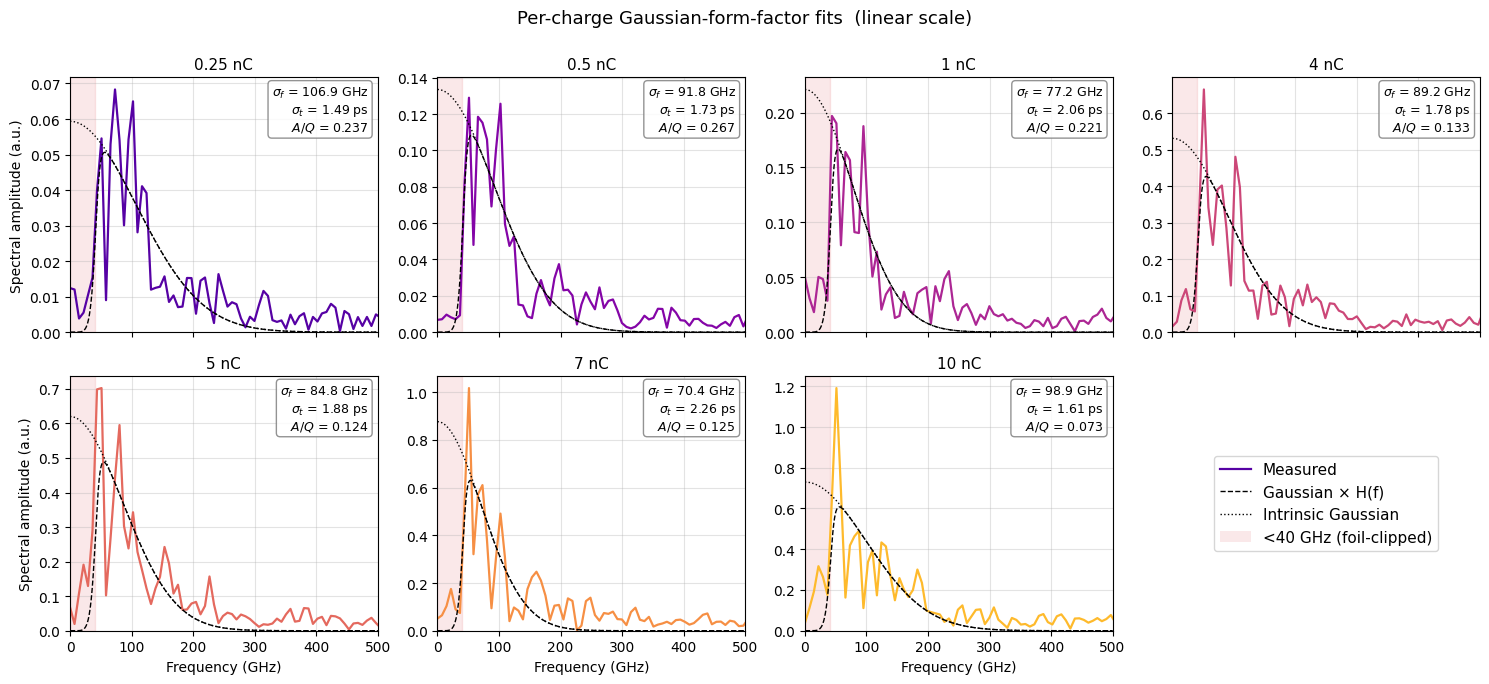

In [11]:
# ── Per-charge subplots: measured + full model + intrinsic Gaussian ──────────
# One panel per charge level so the three curves don't overlap across charges.
# Solid  = measured spectrum.
# Dashed = full model fit  S(f) = A·exp(-f²/2σ²)·H(f; fc, n).
# Dotted = intrinsic Gaussian (cutoff removed) — the modelled low-f content.
n_q       = len(gauss_fits)
ncols     = 4
nrows     = int(np.ceil(n_q / ncols))
colors_g  = plt.cm.plasma(np.linspace(0.15, 0.85, n_q))

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.4*nrows), sharex=True, sharey=False)
axes = np.atleast_2d(axes).ravel()

for i, (g, col) in enumerate(zip(gauss_fits, colors_g)):
    ax = axes[i]
    ax.plot(g['f'],   g['S'],                color=col, lw=1.6, label='Measured')
    ax.plot(F_MODEL,  g['S_full_full'],      color='k', lw=1.0, ls='--', label='Gaussian × H(f)')
    ax.plot(F_MODEL,  g['S_intrinsic_full'], color='k', lw=1.0, ls=':',  label='Intrinsic Gaussian')
    ax.axvspan(0, F_CUT_GHZ, color='C3', alpha=0.10)
    ax.set_xlim(0, 500)
    ax.set_ylim(bottom=0)
    ax.grid(True, alpha=0.35)
    # Annotate fit parameters
    txt = (fr"$\sigma_f$ = {g['sigma']:.1f} GHz"
           "\n"
           fr"$\sigma_t$ = {g['sigma_t_ps']:.2f} ps"
           "\n"
           fr"$A/Q$ = {g['A']/g['Q']:.3f}")
    ax.text(0.97, 0.97, txt, transform=ax.transAxes,
            ha='right', va='top', fontsize=9,
            bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='0.5', alpha=0.85))
    ax.set_title(f"{g['label']}", fontsize=11)
    if i % ncols == 0:
        ax.set_ylabel('Spectral amplitude (a.u.)')
    if i >= ncols*(nrows-1):
        ax.set_xlabel('Frequency (GHz)')

# Hide any unused panels
for j in range(n_q, len(axes)):
    axes[j].set_visible(False)

# Single shared legend in the first empty slot (or above the figure)
handles, labels = axes[0].get_legend_handles_labels()
handles.append(plt.Rectangle((0,0),1,1, fc='C3', alpha=0.10))
labels.append(f'<{F_CUT_GHZ:.0f} GHz (foil-clipped)')
if n_q < len(axes):
    leg_ax = axes[n_q]
    leg_ax.set_visible(True); leg_ax.axis('off')
    leg_ax.legend(handles, labels, loc='center', fontsize=11, frameon=True)
else:
    fig.legend(handles, labels, loc='upper center', ncol=4, fontsize=10,
               bbox_to_anchor=(0.5, 1.02))

fig.suptitle('Per-charge Gaussian-form-factor fits  (linear scale)',
             fontsize=13, y=1.00)
plt.tight_layout()
plt.savefig('Results/gaussian_fits_per_charge.png', dpi=200, bbox_inches='tight')
plt.show()


### Pure-Gaussian fit per charge (peak-pinned f0, no foil-cutoff convolution)

Without modeling the foil cutoff, a single Gaussian can't span both the cutoff-shaped rising edge and the bunch-shaped falling edge of the visible spectrum. The cleanest workaround:

- Find f0 from the smoothed-data argmax in 25-200 GHz (the visible spectral peak).
- Fit only A and sigma to the **right of the peak** (where the bunch shape is unambiguous, not the foil).

The Gaussian is therefore guaranteed to sit centred on the visible hump, and sigma directly measures the high-frequency rolloff.

 Q (nC)           A    f0 (GHz)   sigma_f (GHz)   FWHM (GHz)
   0.25       0.045       87.75           44.14       103.93
   0.50       0.113       65.81           44.36       104.47
   1.00       0.128       58.50           55.36       130.36
   4.00       0.307       65.81           69.05       162.60
   5.00       0.303       58.50           86.10       202.76
   7.00       0.357       58.50           81.44       191.77
  10.00       0.392       58.50          102.16       240.58


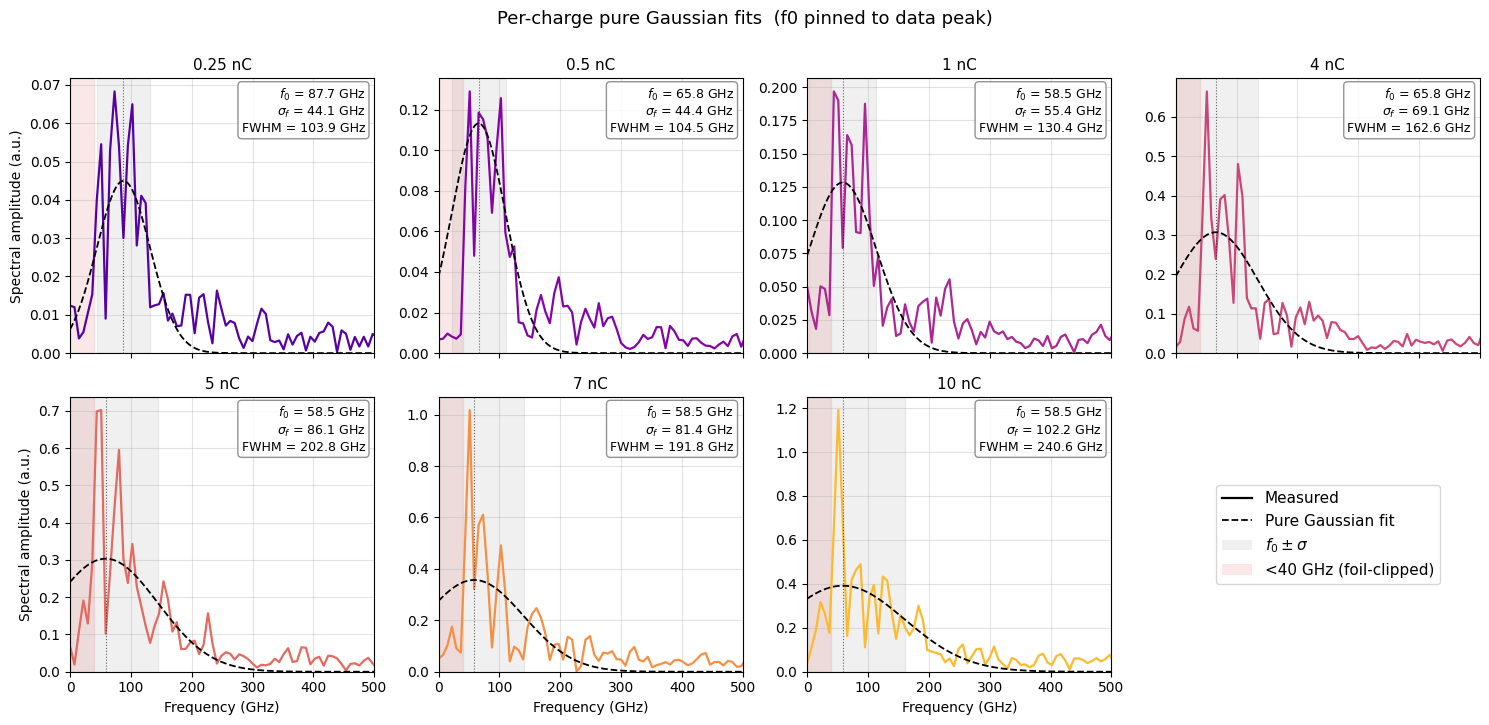

In [12]:
# ── Pure-Gaussian fit per charge: f0 pinned to data peak ────────────────────
def gaussian_free(f, A, f0, sigma):
    return A * np.exp(-0.5 * ((f - f0) / sigma) ** 2)

def _smooth(y, w):
    if w <= 1: return y
    return np.convolve(y, np.ones(w)/w, mode='same')

PEAK_SEARCH  = (25.0, 200.0)
RIGHT_HI_GHZ = 350.0
SMOOTH_BINS  = 5

peak_fits = []
for sp in spectra:
    f, S = sp['freq_GHz'], sp['spec']
    Ss = _smooth(S, SMOOTH_BINS)
    pkm = (f >= PEAK_SEARCH[0]) & (f <= PEAK_SEARCH[1])
    pk_idx = np.where(pkm)[0][Ss[pkm].argmax()]
    f0_pin = float(f[pk_idx])

    right = (f >= f0_pin) & (f <= RIGHT_HI_GHZ)
    def _gauss_pinned(ff, A, sigma, _f0=f0_pin):
        return A * np.exp(-0.5*((ff - _f0)/sigma)**2)
    try:
        popt, _ = curve_fit(
            _gauss_pinned, f[right], S[right],
            p0=[float(S[pk_idx]), 60.0],
            bounds=([0.0, 10.0], [np.inf, 300.0]),
            maxfev=8000,
        )
        A, sig = popt
    except Exception as exc:
        print(f"  fit failed for {sp['label']}: {exc}")
        A = sig = float('nan')

    peak_fits.append({
        'Q': sp['Q'], 'label': sp['label'],
        'A': A, 'f0': f0_pin, 'sigma': sig,
        'fwhm': 2.3548 * sig,
        'S_curve': gaussian_free(F_MODEL, A, f0_pin, sig),
    })

print(f"{'Q (nC)':>7}  {'A':>10}  {'f0 (GHz)':>10}  {'sigma_f (GHz)':>14}  {'FWHM (GHz)':>11}")
for g in peak_fits:
    print(f"{g['Q']:7.2f}  {g['A']:10.3g}  {g['f0']:10.2f}  {g['sigma']:14.2f}  {g['fwhm']:11.2f}")

# ── Per-charge subplots ──────────────────────────────────────────────────────
n_q   = len(peak_fits)
ncols = 4
nrows = int(np.ceil(n_q / ncols))
cols  = plt.cm.plasma(np.linspace(0.15, 0.85, n_q))

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.6*nrows), sharex=True)
axes = np.atleast_2d(axes).ravel()

for i, (g, col) in enumerate(zip(peak_fits, cols)):
    ax = axes[i]
    f, S = spectra[i]['freq_GHz'], spectra[i]['spec']
    ax.plot(f, S, color=col, lw=1.6, label='Measured')
    ax.plot(F_MODEL, g['S_curve'], color='k', lw=1.3, ls='--', label='Pure Gaussian fit')
    ax.axvline(g['f0'], color='k', ls=':', lw=0.8, alpha=0.6)
    ax.axvspan(g['f0']-g['sigma'], g['f0']+g['sigma'], color='k', alpha=0.06)
    ax.axvspan(0, F_CUT_GHZ, color='C3', alpha=0.10)
    ax.set_xlim(0, 500)
    ax.set_ylim(bottom=0)
    ax.grid(True, alpha=0.35)
    txt = (fr"$f_0$ = {g['f0']:.1f} GHz" + "\n"
           fr"$\sigma_f$ = {g['sigma']:.1f} GHz" + "\n"
           fr"FWHM = {g['fwhm']:.1f} GHz")
    ax.text(0.97, 0.97, txt, transform=ax.transAxes,
            ha='right', va='top', fontsize=9,
            bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='0.5', alpha=0.85))
    ax.set_title(g['label'], fontsize=11)
    if i % ncols == 0:
        ax.set_ylabel('Spectral amplitude (a.u.)')
    if i >= ncols*(nrows-1):
        ax.set_xlabel('Frequency (GHz)')

for j in range(n_q, len(axes)):
    axes[j].set_visible(False)

if n_q < len(axes):
    leg_ax = axes[n_q]; leg_ax.set_visible(True); leg_ax.axis('off')
    leg_handles = [
        plt.Line2D([0],[0], color='k', lw=1.6, label='Measured'),
        plt.Line2D([0],[0], color='k', lw=1.3, ls='--', label='Pure Gaussian fit'),
        plt.Rectangle((0,0),1,1, fc='k', alpha=0.06, label=r'$f_0 \pm \sigma$'),
        plt.Rectangle((0,0),1,1, fc='C3', alpha=0.10, label=f'<{F_CUT_GHZ:.0f} GHz (foil-clipped)'),
    ]
    leg_ax.legend(handles=leg_handles, loc='center', fontsize=11, frameon=True)

fig.suptitle('Per-charge pure Gaussian fits  (f0 pinned to data peak)',
             fontsize=13, y=1.00)
plt.tight_layout()
plt.savefig('Results/gaussian_pure_fits_per_charge.png', dpi=200, bbox_inches='tight')
plt.show()


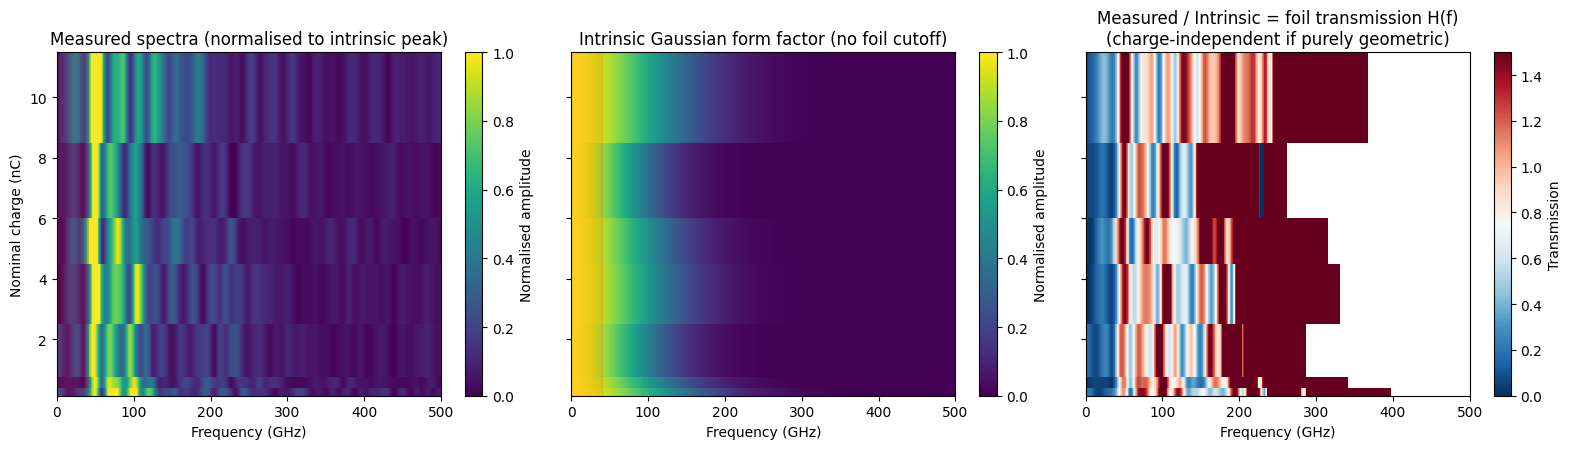

In [13]:
# ── Heatmap comparison: measured vs intrinsic Gaussian vs foil transmission ──
# Left  : measured spectra (clipped by the foil) on a common frequency grid.
# Centre: intrinsic Gaussian form factor (extrapolated through the clipped band).
# Right : ratio = measured / intrinsic — directly visualises foil transmission H(f).
#         If H is purely instrumental, the column structure is independent of
#         charge (every row looks the same).
freq_grid = np.linspace(0.0, 500.0, 600)
Q_axis    = np.array([g['Q'] for g in gauss_fits])

meas_mat  = np.zeros((len(gauss_fits), len(freq_grid)))
model_mat = np.zeros_like(meas_mat)
for i, g in enumerate(gauss_fits):
    cs   = CubicSpline(g['f'], g['S'])
    meas_mat[i]  = np.clip(cs(freq_grid), 0, None)
    model_mat[i] = gaussian_at_zero(freq_grid, g['A'], g['sigma'])
    # Normalise each row by the intrinsic-Gaussian peak (always at f=0)
    pk = max(model_mat[i].max(), 1e-12)
    meas_mat[i]  /= pk
    model_mat[i] /= pk
ratio_mat = np.where(model_mat > 1e-3, meas_mat / model_mat, np.nan)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)

pcm0 = axes[0].pcolormesh(freq_grid, Q_axis, meas_mat,  cmap='viridis', vmin=0, vmax=1, shading='auto')
axes[0].set_title('Measured spectra (normalised to intrinsic peak)')
plt.colorbar(pcm0, ax=axes[0], label='Normalised amplitude')

pcm1 = axes[1].pcolormesh(freq_grid, Q_axis, model_mat, cmap='viridis', vmin=0, vmax=1, shading='auto')
axes[1].set_title('Intrinsic Gaussian form factor (no foil cutoff)')
plt.colorbar(pcm1, ax=axes[1], label='Normalised amplitude')

for ax in axes[:2]:
    ax.axvspan(0, F_CUT_GHZ, color='red', alpha=0.10)
    ax.set_xlabel('Frequency (GHz)')
axes[0].set_ylabel('Nominal charge (nC)')

pcm2 = axes[2].pcolormesh(freq_grid, Q_axis, ratio_mat, cmap='RdBu_r', vmin=0, vmax=1.5, shading='auto')
axes[2].set_title('Measured / Intrinsic = foil transmission H(f)\n(charge-independent if purely geometric)')
axes[2].axvspan(0, F_CUT_GHZ, color='k', alpha=0.05)
axes[2].set_xlabel('Frequency (GHz)')
plt.colorbar(pcm2, ax=axes[2], label='Transmission')

for ax in axes:
    ax.set_xlim(0, 500)
plt.tight_layout()
plt.savefig('Results/gaussian_model_heatmaps.png', dpi=200, bbox_inches='tight')
plt.show()

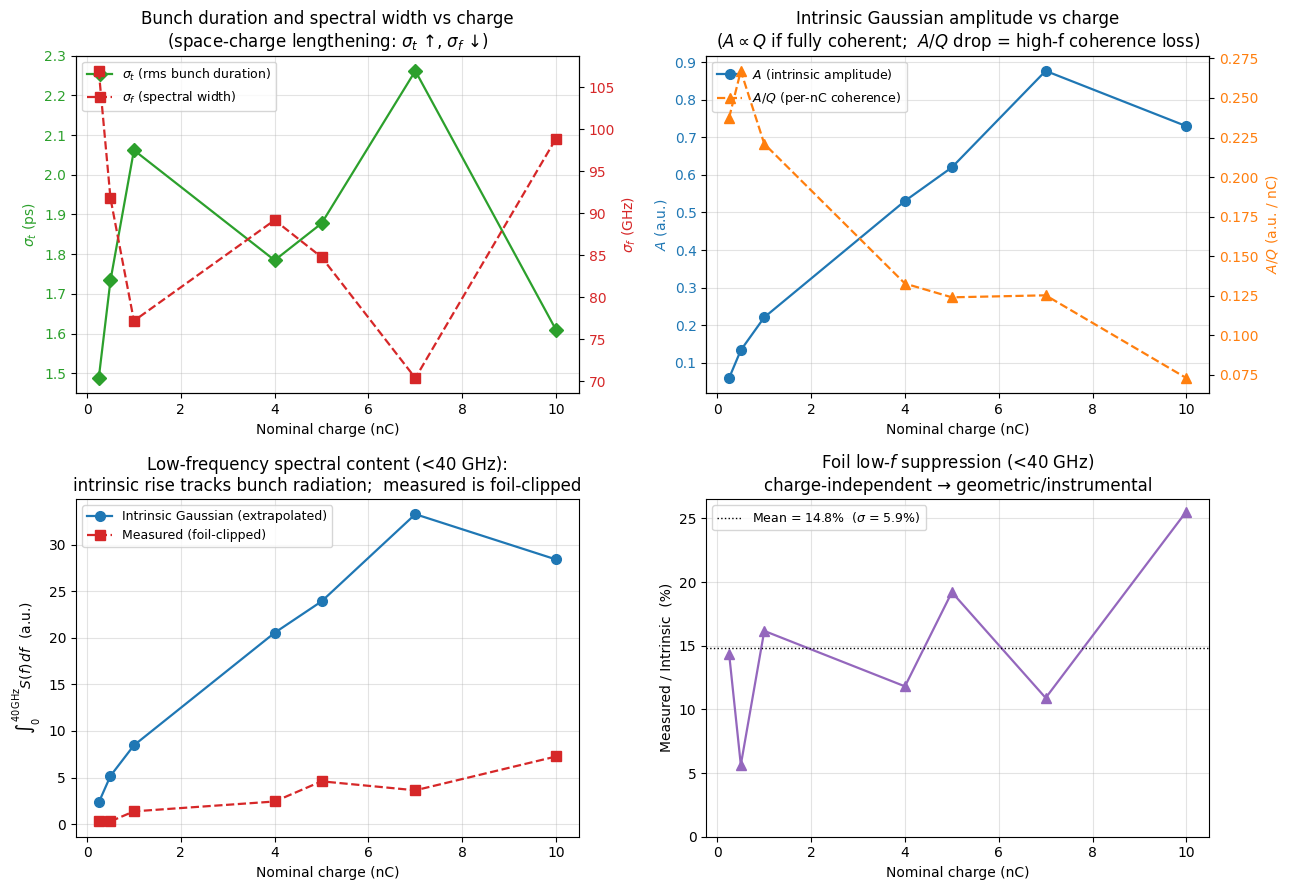


Gaussian-modeled (intrinsic) low-frequency content vs measured (<40 GHz):
  Intrinsic <40 GHz integral spans 2.32 → 28.4  (12.2× over 0.25→10.0 nC)
  Measured  <40 GHz integral spans 0.334 → 7.26  (21.8×)
  Mean measured/intrinsic = 14.8 ± 5.9%  (charge-independent → consistent with a fixed geometric cutoff)

Bunch duration trend: σ_t = 1.49 ps at 0.25 nC  →  1.61 ps at 10.0 nC   (1.08× lengthening from space charge)
Per-nC coherent amplitude A/Q: 0.237 → 0.073  (31% of low-Q value at high Q)


In [14]:
# ── Fit parameters and modeled low-f content vs charge ──────────────────────
Q_g     = np.array([g['Q']         for g in gauss_fits])
A_g     = np.array([g['A']         for g in gauss_fits])
sig_g   = np.array([g['sigma']     for g in gauss_fits])
sigT_g  = np.array([g['sigma_t_ps'] for g in gauss_fits])
meas_lo = np.array([g['meas_lo']   for g in gauss_fits])
mod_lo  = np.array([g['mod_lo']    for g in gauss_fits])
supp_g  = meas_lo / mod_lo

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# (a) Bunch duration σ_t and Gaussian width σ_f vs charge (twin axes)
ax = axes[0, 0]
ax2 = ax.twinx()
ax.plot(Q_g,  sigT_g, 'C2D-',  lw=1.6, ms=7, label=r'$\sigma_t$ (rms bunch duration)')
ax2.plot(Q_g, sig_g,  'C3s--', lw=1.6, ms=7, label=r'$\sigma_f$ (spectral width)')
ax.set_xlabel('Nominal charge (nC)')
ax.set_ylabel(r'$\sigma_t$ (ps)', color='C2')
ax2.set_ylabel(r'$\sigma_f$ (GHz)', color='C3')
ax.tick_params(axis='y', labelcolor='C2'); ax2.tick_params(axis='y', labelcolor='C3')
ax.set_title('Bunch duration and spectral width vs charge\n(space-charge lengthening: $\\sigma_t$ ↑, $\\sigma_f$ ↓)')
ax.grid(True, alpha=0.35)
lines1, labs1 = ax.get_legend_handles_labels()
lines2, labs2 = ax2.get_legend_handles_labels()
ax.legend(lines1+lines2, labs1+labs2, fontsize=9, loc='upper left')

# (b) Coherent amplitude A and A/Q vs charge
ax = axes[0, 1]
ax2 = ax.twinx()
ax.plot(Q_g, A_g, 'C0o-', lw=1.6, ms=7, label=r'$A$ (intrinsic amplitude)')
ax2.plot(Q_g, A_g/Q_g, 'C1^--', lw=1.6, ms=7, label=r'$A/Q$ (per-nC coherence)')
ax.set_xlabel('Nominal charge (nC)')
ax.set_ylabel(r'$A$ (a.u.)', color='C0')
ax2.set_ylabel(r'$A/Q$ (a.u. / nC)', color='C1')
ax.tick_params(axis='y', labelcolor='C0'); ax2.tick_params(axis='y', labelcolor='C1')
ax.set_title('Intrinsic Gaussian amplitude vs charge\n($A \\propto Q$ if fully coherent;  $A/Q$ drop = high-f coherence loss)')
ax.grid(True, alpha=0.35)
lines1, labs1 = ax.get_legend_handles_labels()
lines2, labs2 = ax2.get_legend_handles_labels()
ax.legend(lines1+lines2, labs1+labs2, fontsize=9, loc='upper left')

# (c) Modeled (intrinsic) vs measured low-frequency content (integrated <40 GHz)
ax = axes[1, 0]
ax.plot(Q_g, mod_lo,  'C0o-',  lw=1.6, ms=7, label='Intrinsic Gaussian (extrapolated)')
ax.plot(Q_g, meas_lo, 'C3s--', lw=1.6, ms=7, label='Measured (foil-clipped)')
ax.set_xlabel('Nominal charge (nC)')
ax.set_ylabel(fr'$\int_0^{{{F_CUT_GHZ:.0f}\,\rm GHz}} S(f)\,df$  (a.u.)')
ax.set_title(f'Low-frequency spectral content (<{F_CUT_GHZ:.0f} GHz):\n'
             f'intrinsic rise tracks bunch radiation;  measured is foil-clipped')
ax.legend(fontsize=9); ax.grid(True, alpha=0.35)

# (d) Suppression ratio = measured / intrinsic (should be charge-independent)
ax = axes[1, 1]
ax.plot(Q_g, 100*supp_g, 'C4^-', lw=1.6, ms=7)
ax.axhline(100*np.nanmean(supp_g), color='k', ls=':', lw=1.0,
           label=fr'Mean = {100*np.nanmean(supp_g):.1f}%  ($\sigma$ = {100*np.nanstd(supp_g):.1f}%)')
ax.set_xlabel('Nominal charge (nC)')
ax.set_ylabel('Measured / Intrinsic  (%)')
ax.set_title(f'Foil low-$f$ suppression (<{F_CUT_GHZ:.0f} GHz)\ncharge-independent → geometric/instrumental')
ax.set_ylim(bottom=0)
ax.legend(fontsize=9); ax.grid(True, alpha=0.35)

plt.tight_layout()
plt.savefig('Results/gaussian_fit_trends_vs_charge.png', dpi=200, bbox_inches='tight')
plt.show()

print(f"\nGaussian-modeled (intrinsic) low-frequency content vs measured (<{F_CUT_GHZ:.0f} GHz):")
print(f"  Intrinsic <40 GHz integral spans {mod_lo[0]:.3g} → {mod_lo[-1]:.3g}  "
      f"({mod_lo[-1]/mod_lo[0]:.1f}× over {Q_g[0]:.2f}→{Q_g[-1]:.1f} nC)")
print(f"  Measured  <40 GHz integral spans {meas_lo[0]:.3g} → {meas_lo[-1]:.3g}  "
      f"({meas_lo[-1]/meas_lo[0]:.1f}×)")
print(f"  Mean measured/intrinsic = {100*np.nanmean(supp_g):.1f} ± {100*np.nanstd(supp_g):.1f}%  "
      f"(charge-independent → consistent with a fixed geometric cutoff)")
print(f"\nBunch duration trend: σ_t = {sigT_g[0]:.2f} ps at {Q_g[0]:.2f} nC  →  "
      f"{sigT_g[-1]:.2f} ps at {Q_g[-1]:.1f} nC   ({sigT_g[-1]/sigT_g[0]:.2f}× lengthening from space charge)")
print(f"Per-nC coherent amplitude A/Q: {A_g[0]/Q_g[0]:.3g} → {A_g[-1]/Q_g[-1]:.3g}  "
      f"({100*(A_g[-1]/Q_g[-1])/(A_g[0]/Q_g[0]):.0f}% of low-Q value at high Q)")


## Section 3d: IFFT of the Intrinsic Gaussian — Recovered Bunch Geometry

The Section 3c fit extracted the bunch's intrinsic amplitude form factor

$$|F(f)| = A\,\exp\!\big[-f^2/(2\sigma_f^2)\big]$$

with the foil cutoff $H(f)$ removed analytically. Inverse-Fourier-transforming this gives the bunch's longitudinal charge profile in time:

$$\rho(t) \;=\; \int |F(f)|\, e^{2\pi i f t}\, df \;=\; \sqrt{2\pi}\,A\,\sigma_f\,\exp\!\big[-t^2/(2\sigma_t^2)\big],\qquad \sigma_t = \frac{1}{2\pi\sigma_f}.$$

So the recovered bunch geometry is necessarily a Gaussian whose rms duration is fixed by the spectral width — that's the model's content. The IFFT below verifies the numerical recovery matches the analytic Gaussian, and the overlay plot shows the bunch lengthening with charge that drives the spectral narrowing observed in Section 3c.

 Q (nC)   sigma_f (GHz)   sigma_t analytic (ps)   sigma_t IFFT (ps)
   0.25          106.93                   1.488               1.488
   0.50           91.76                   1.734               1.734
   1.00           77.19                   2.062               2.062
   4.00           89.17                   1.785               1.785
   5.00           84.77                   1.878               1.878
   7.00           70.38                   2.261               2.261
  10.00           98.88                   1.610               1.610


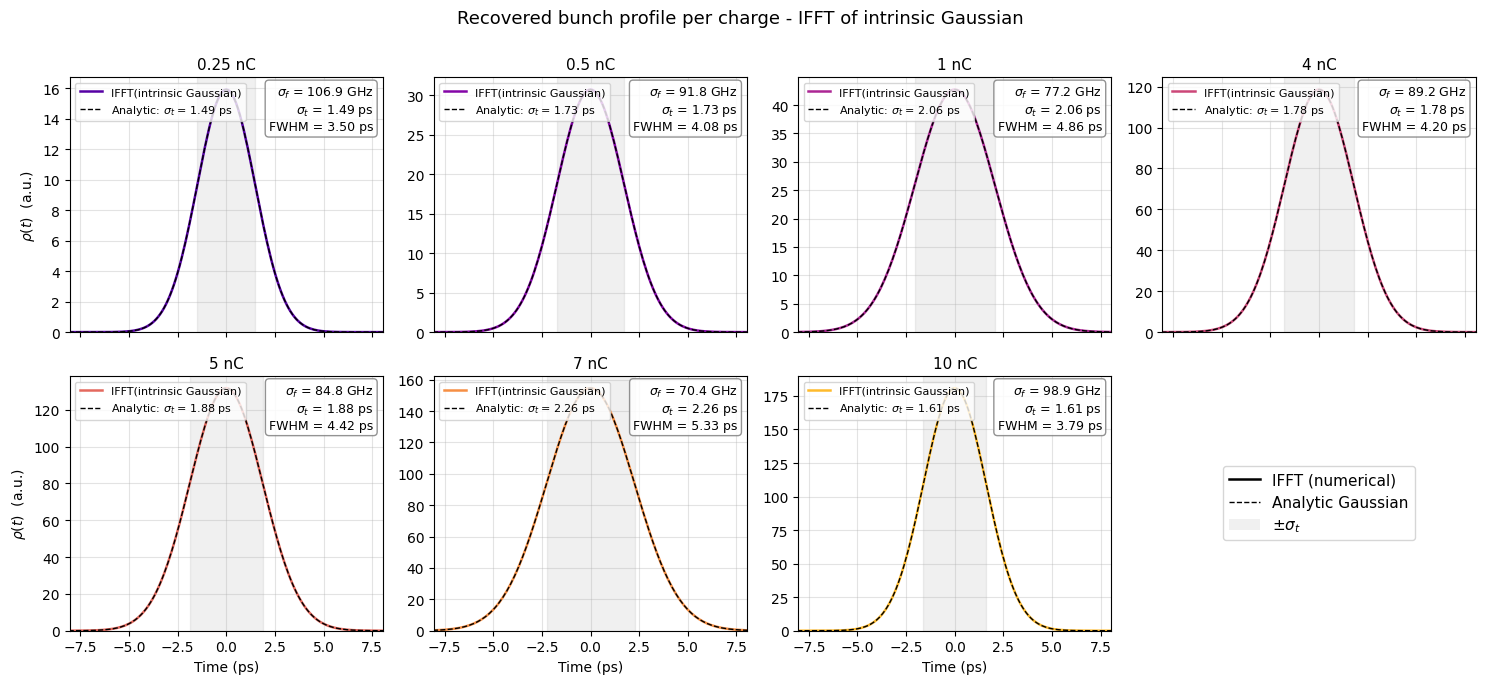

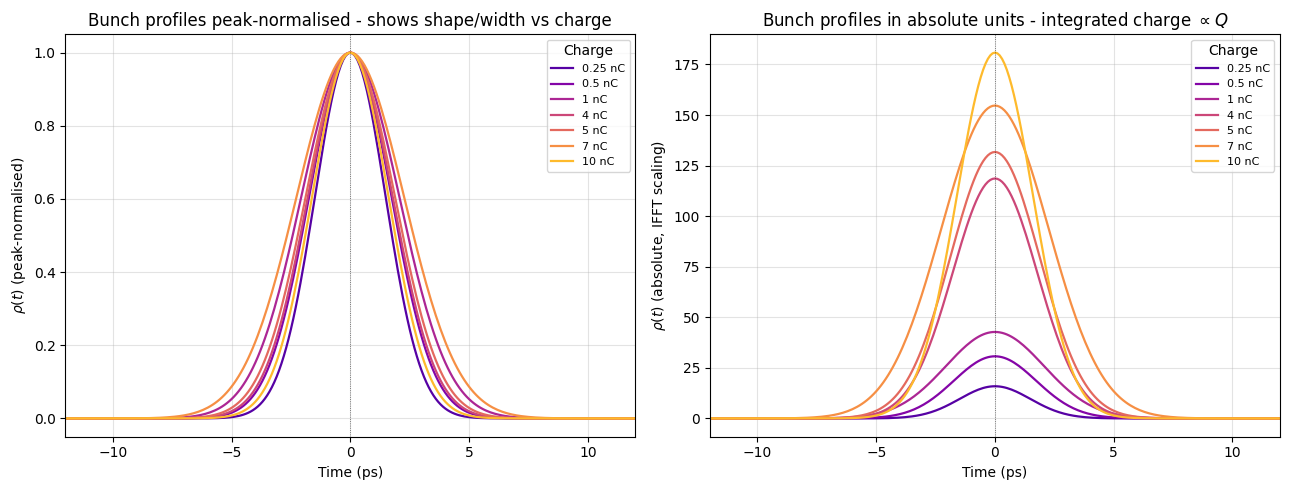


Bunch duration trend (recovered from IFFT):
  sigma_t = 1.49 ps at 0.25 nC
  sigma_t = 1.61 ps at 10.0 nC
  Lengthening factor: 1.08x


In [15]:
# ── Section 3d: IFFT of intrinsic Gaussian -> recovered bunch profile ───────
# Build a symmetric (rfft-style) frequency grid, evaluate each charge's
# intrinsic Gaussian on it, and take the real inverse FFT.
N_TIME = 4096
DT_PS  = 0.1                                  # 0.1 ps time resolution
T_TOT  = N_TIME * DT_PS                       # ~410 ps total window
DF_GHZ = 1e3 / T_TOT                          # GHz frequency bin
F_IFFT = np.arange(N_TIME//2 + 1) * DF_GHZ    # one-sided spectrum for irfft
t_ifft = (np.arange(N_TIME) - N_TIME//2) * DT_PS

bunch_recovered = []
for g in gauss_fits:
    A, sigma_f = g['A'], g['sigma']
    F = A * np.exp(-0.5 * (F_IFFT / sigma_f) ** 2)
    rho = np.fft.fftshift(np.fft.irfft(F, n=N_TIME)) * DF_GHZ * N_TIME   # continuous-FT scaling

    sigma_t_ps = 1e3 / (2 * np.pi * sigma_f)
    rho_analytic = np.sqrt(2*np.pi) * A * sigma_f * np.exp(-0.5*(t_ifft/sigma_t_ps)**2)

    # rms width measured directly from the numerical IFFT (sanity check)
    rho_norm = rho - rho.min()
    rho_norm /= rho_norm.sum()
    sigma_t_meas = float(np.sqrt(np.sum(rho_norm * t_ifft**2)))

    bunch_recovered.append({
        'Q': g['Q'], 'label': g['label'],
        'A': A, 'sigma_f': sigma_f,
        'sigma_t_ps': sigma_t_ps, 'sigma_t_meas': sigma_t_meas,
        't': t_ifft, 'rho': rho, 'rho_analytic': rho_analytic,
    })

print(f"{'Q (nC)':>7}  {'sigma_f (GHz)':>14}  {'sigma_t analytic (ps)':>22}  {'sigma_t IFFT (ps)':>18}")
for b in bunch_recovered:
    print(f"{b['Q']:7.2f}  {b['sigma_f']:14.2f}  {b['sigma_t_ps']:22.3f}  {b['sigma_t_meas']:18.3f}")

# ── Per-charge subplots: IFFT vs analytic Gaussian ──────────────────────────
n_q   = len(bunch_recovered)
ncols = 4
nrows = int(np.ceil(n_q / ncols))
cols  = plt.cm.plasma(np.linspace(0.15, 0.85, n_q))

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.4*nrows), sharex=True)
axes = np.atleast_2d(axes).ravel()

for i, (b, col) in enumerate(zip(bunch_recovered, cols)):
    ax = axes[i]
    # Center-zoom to ~5σ of the widest expected bunch
    half = max(8.0, 5*b['sigma_t_ps'])
    ax.plot(b['t'], b['rho'],          color=col, lw=1.8, label='IFFT(intrinsic Gaussian)')
    ax.plot(b['t'], b['rho_analytic'], color='k', lw=1.0, ls='--',
            label=fr"Analytic: $\sigma_t$ = {b['sigma_t_ps']:.2f} ps")
    ax.axvspan(-b['sigma_t_ps'], b['sigma_t_ps'], color='k', alpha=0.06)
    ax.set_xlim(-half, half)
    ax.set_ylim(bottom=0)
    ax.grid(True, alpha=0.35)
    ax.set_title(b['label'], fontsize=11)
    txt = (fr"$\sigma_f$ = {b['sigma_f']:.1f} GHz" + "\n"
           fr"$\sigma_t$ = {b['sigma_t_ps']:.2f} ps" + "\n"
           fr"FWHM = {2.3548*b['sigma_t_ps']:.2f} ps")
    ax.text(0.97, 0.97, txt, transform=ax.transAxes,
            ha='right', va='top', fontsize=9,
            bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='0.5', alpha=0.85))
    if i % ncols == 0:
        ax.set_ylabel(r'$\rho(t)$  (a.u.)')
    if i >= ncols*(nrows-1):
        ax.set_xlabel('Time (ps)')
    ax.legend(fontsize=8, loc='upper left')

for j in range(n_q, len(axes)):
    axes[j].set_visible(False)

if n_q < len(axes):
    leg_ax = axes[n_q]; leg_ax.set_visible(True); leg_ax.axis('off')
    leg_handles = [
        plt.Line2D([0],[0], color='k', lw=1.8, label='IFFT (numerical)'),
        plt.Line2D([0],[0], color='k', lw=1.0, ls='--', label='Analytic Gaussian'),
        plt.Rectangle((0,0),1,1, fc='k', alpha=0.06, label=r'$\pm\sigma_t$'),
    ]
    leg_ax.legend(handles=leg_handles, loc='center', fontsize=11, frameon=True)

fig.suptitle('Recovered bunch profile per charge - IFFT of intrinsic Gaussian',
             fontsize=13, y=1.00)
plt.tight_layout()
plt.savefig('Results/bunch_ifft_per_charge.png', dpi=200, bbox_inches='tight')
plt.show()

# ── Overlay: all charges, peak-normalised, showing bunch lengthening ────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
for b, col in zip(bunch_recovered, cols):
    rho_n = b['rho'] / b['rho'].max()
    ax1.plot(b['t'], rho_n,                 color=col, lw=1.6, label=b['label'])
    ax2.plot(b['t'], b['rho'],              color=col, lw=1.6, label=b['label'])

for ax in (ax1, ax2):
    ax.axvline(0, color='k', ls=':', lw=0.6, alpha=0.6)
    ax.set_xlim(-12, 12)
    ax.set_xlabel('Time (ps)')
    ax.grid(True, alpha=0.35)
    ax.legend(title='Charge', fontsize=8, loc='upper right')
ax1.set_ylabel(r'$\rho(t)$ (peak-normalised)')
ax1.set_title('Bunch profiles peak-normalised - shows shape/width vs charge')
ax2.set_ylabel(r'$\rho(t)$ (absolute, IFFT scaling)')
ax2.set_title(r'Bunch profiles in absolute units - integrated charge $\propto Q$')

plt.tight_layout()
plt.savefig('Results/bunch_ifft_overlay.png', dpi=200, bbox_inches='tight')
plt.show()

print(f"\nBunch duration trend (recovered from IFFT):")
print(f"  sigma_t = {bunch_recovered[0]['sigma_t_ps']:.2f} ps at {bunch_recovered[0]['Q']:.2f} nC")
print(f"  sigma_t = {bunch_recovered[-1]['sigma_t_ps']:.2f} ps at {bunch_recovered[-1]['Q']:.1f} nC")
print(f"  Lengthening factor: {bunch_recovered[-1]['sigma_t_ps']/bunch_recovered[0]['sigma_t_ps']:.2f}x")


### Sanity check — measured EO signal vs recovered Gaussian bunch

Two reasons the two shapes will NOT be identical:

1. **Foil low-frequency clipping.** The measured EO signal is the THz pulse *as transmitted by the foil*; the recovered bunch is the *intrinsic* Gaussian with the cutoff `H(f)` analytically removed. The EO signal will therefore show negative excursions (the time-domain signature of removing DC and low-f content), while the recovered Gaussian stays strictly positive.
2. **Single-particle radiation response and detector bandwidth.** Both are assumed flat in our model. In reality they add their own mild shaping.

The meaningful comparison is the **central FWHM** — if the EO pulse's main lobe has a similar width to the recovered Gaussian, the form-factor fit is consistent with the measurement.

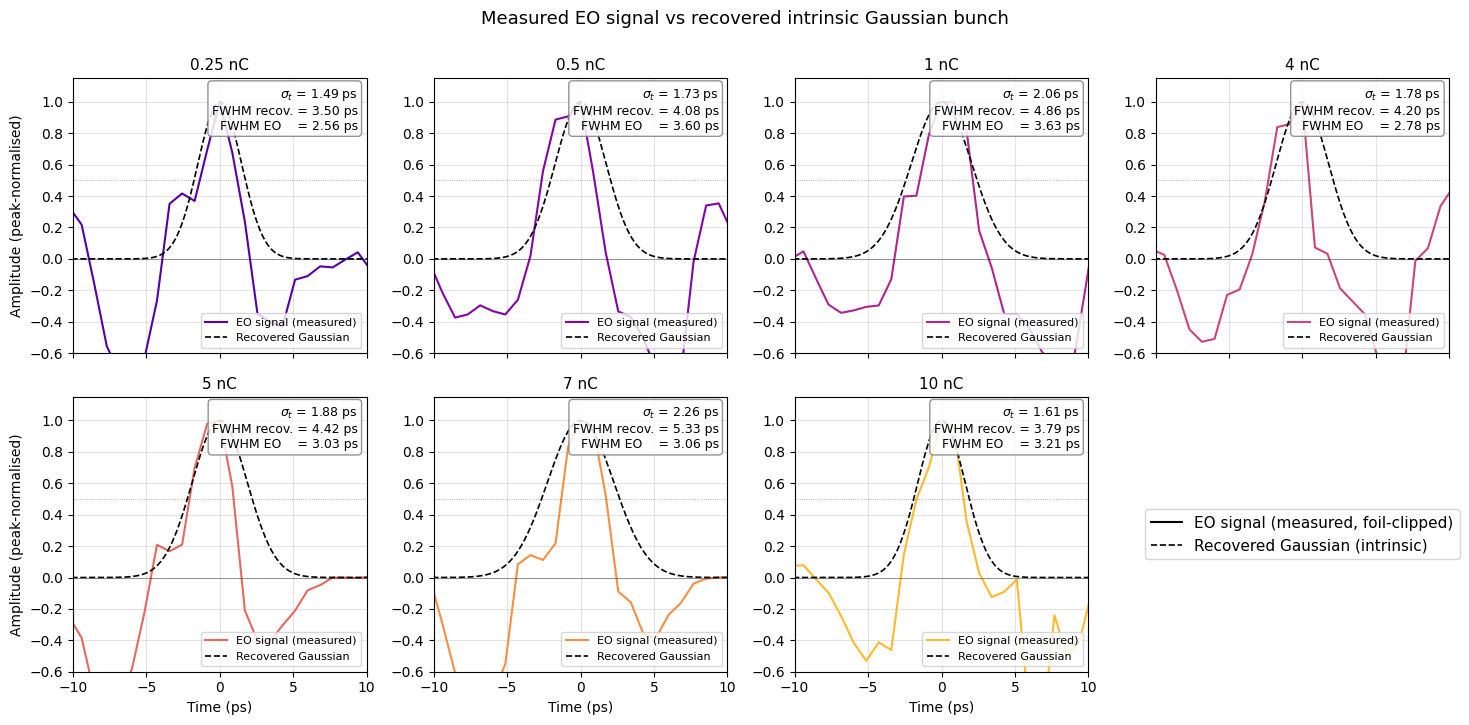

 Q (nC)    FWHM EO (ps)   FWHM recovered (ps)  ratio EO/rec
   0.25            2.56                  3.50          0.73
   0.50            3.60                  4.08          0.88
   1.00            3.63                  4.86          0.75
   4.00            2.78                  4.20          0.66
   5.00            3.03                  4.42          0.69
   7.00            3.06                  5.33          0.58
  10.00            3.21                  3.79          0.85


In [16]:
# ── Measured EO signal vs recovered Gaussian bunch (per charge) ─────────────
def _fwhm_of(t, y):
    """Numerical FWHM via linear interpolation around the global peak."""
    if not np.isfinite(y).any() or y.max() <= 0:
        return float('nan')
    ymax = y.max()
    half = 0.5 * ymax
    ipk  = int(y.argmax())
    # Left crossing
    left = y[:ipk+1]
    lc   = np.where(np.diff(np.sign(left - half)))[0]
    if len(lc) == 0:
        tL = t[0]
    else:
        i = lc[-1]
        tL = t[i] + (t[i+1]-t[i]) * (half - y[i]) / (y[i+1] - y[i])
    # Right crossing
    right = y[ipk:]
    rc    = np.where(np.diff(np.sign(right - half)))[0]
    if len(rc) == 0:
        tR = t[-1]
    else:
        i = ipk + rc[0]
        tR = t[i] + (t[i+1]-t[i]) * (half - y[i]) / (y[i+1] - y[i])
    return tR - tL

n_q   = len(bunch_recovered)
ncols = 4
nrows = int(np.ceil(n_q / ncols))
cols  = plt.cm.plasma(np.linspace(0.15, 0.85, n_q))

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.6*nrows), sharex=True)
axes = np.atleast_2d(axes).ravel()

for i, (b, r, col) in enumerate(zip(bunch_recovered, results, cols)):
    ax = axes[i]

    # Measured EO signal: centre on absolute peak, scale to max |sig| = 1
    sig    = r['sig'].copy()
    dp     = r['delay_ps']
    pk_idx = int(np.abs(sig).argmax())
    # Choose sign so the dominant lobe is positive (EO polarity can flip)
    sign   = 1.0 if sig[pk_idx] > 0 else -1.0
    sig_n  = sign * sig / np.abs(sig).max()
    t_meas = dp - dp[pk_idx]

    # Recovered bunch (peak-normalised, t already centred at 0)
    rho_n = b['rho'] / b['rho'].max()

    ax.plot(t_meas, sig_n, color=col, lw=1.5, label='EO signal (measured)')
    ax.plot(b['t'], rho_n, color='k', lw=1.2, ls='--', label='Recovered Gaussian')
    ax.axhline(0,  color='k', lw=0.5, alpha=0.5)
    ax.axhline(0.5, color='k', ls=':', lw=0.6, alpha=0.4)

    # FWHM measurements
    fwhm_eo  = _fwhm_of(t_meas, np.clip(sig_n, 0, None))
    fwhm_rec = 2.3548 * b['sigma_t_ps']

    half = max(10.0, 4*b['sigma_t_ps'])
    ax.set_xlim(-half, half)
    ax.set_ylim(-0.6, 1.15)
    ax.grid(True, alpha=0.35)
    ax.set_title(b['label'], fontsize=11)
    txt = (fr"$\sigma_t$ = {b['sigma_t_ps']:.2f} ps" + "\n"
           f"FWHM recov. = {fwhm_rec:.2f} ps" + "\n"
           f"FWHM EO    = {fwhm_eo:.2f} ps")
    ax.text(0.97, 0.97, txt, transform=ax.transAxes,
            ha='right', va='top', fontsize=9,
            bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='0.5', alpha=0.85))
    if i % ncols == 0:
        ax.set_ylabel('Amplitude (peak-normalised)')
    if i >= ncols*(nrows-1):
        ax.set_xlabel('Time (ps)')
    ax.legend(fontsize=8, loc='lower right')

for j in range(n_q, len(axes)):
    axes[j].set_visible(False)
if n_q < len(axes):
    leg_ax = axes[n_q]; leg_ax.set_visible(True); leg_ax.axis('off')
    leg_handles = [
        plt.Line2D([0],[0], color='k', lw=1.5, label='EO signal (measured, foil-clipped)'),
        plt.Line2D([0],[0], color='k', lw=1.2, ls='--', label='Recovered Gaussian (intrinsic)'),
    ]
    leg_ax.legend(handles=leg_handles, loc='center', fontsize=11, frameon=True)

fig.suptitle('Measured EO signal vs recovered intrinsic Gaussian bunch', fontsize=13, y=1.00)
plt.tight_layout()
plt.savefig('Results/bunch_eo_vs_recovered.png', dpi=200, bbox_inches='tight')
plt.show()

print(f"{'Q (nC)':>7}  {'FWHM EO (ps)':>14}  {'FWHM recovered (ps)':>20}  {'ratio EO/rec':>12}")
for b, r in zip(bunch_recovered, results):
    sig    = r['sig'].copy()
    pk_idx = int(np.abs(sig).argmax())
    sign   = 1.0 if sig[pk_idx] > 0 else -1.0
    sig_n  = sign * sig / np.abs(sig).max()
    t_meas = r['delay_ps'] - r['delay_ps'][pk_idx]
    fwhm_eo  = _fwhm_of(t_meas, np.clip(sig_n, 0, None))
    fwhm_rec = 2.3548 * b['sigma_t_ps']
    ratio    = fwhm_eo / fwhm_rec if fwhm_rec > 0 else float('nan')
    print(f"{b['Q']:7.2f}  {fwhm_eo:14.2f}  {fwhm_rec:20.2f}  {ratio:12.2f}")


## Section 3e: Spectral Padding to "Un-Clip" the BPD Signal

The measured EO/BPD signal is missing its low-frequency content (below ~40 GHz) because the radiative foil's geometric high-pass removes it. The time-domain consequence is the negative undershoots flanking the central positive peak (Section 3d sanity-check plot) - a hallmark of any high-passed pulse.

**Method.** With the Gaussian * Butterworth model in hand we have, per charge, both:

- the foil transfer function $H(f;f_c,n)$ measured in Section 3b, and
- the intrinsic Gaussian amplitude $S_{\rm fit}(f) = A\,\exp[-f^2/(2\sigma_f^2)]$ fit in Section 3c.

The reconstruction uses the **magnitude of the measured spectrum**, adds back the foil-suppressed low-frequency portion from the model, and assumes a real-symmetric (zero-phase) bunch profile:

$$|Z_{\rm recon}(f)| \;=\; |Z_{\rm meas}(f)| \;+\; \big(1-H(f)\big)\,S_{\rm fit}(f)$$

The weight $(1-H)$ is the natural blend: $\approx 0$ where the foil transmits (data is good) and $\approx 1$ where the foil clips (use the model). Taking the inverse FFT of this positive-real spectrum with zero phase yields a centred symmetric bunch profile - no per-charge time-origin estimation needed, no phase artefacts.

This is consistent with the symmetric-Gaussian model already built into the form-factor fit. If you wanted to preserve the bunch's actual time asymmetry you would need to keep the measured complex phase, which is unreliable at the very low frequencies where this reconstruction matters most.

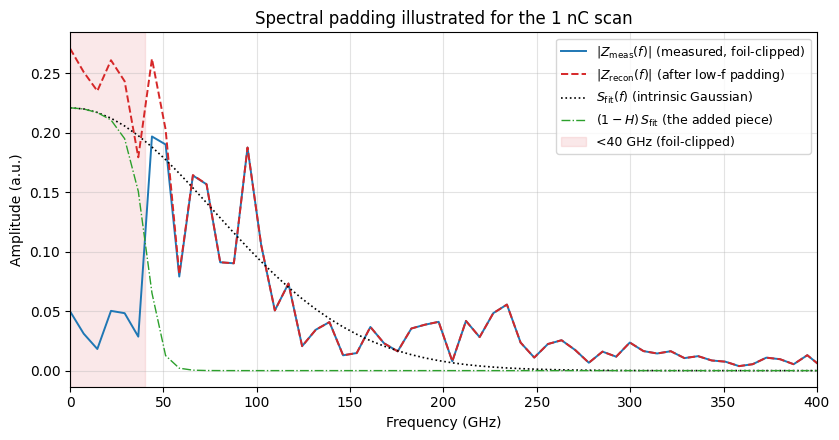

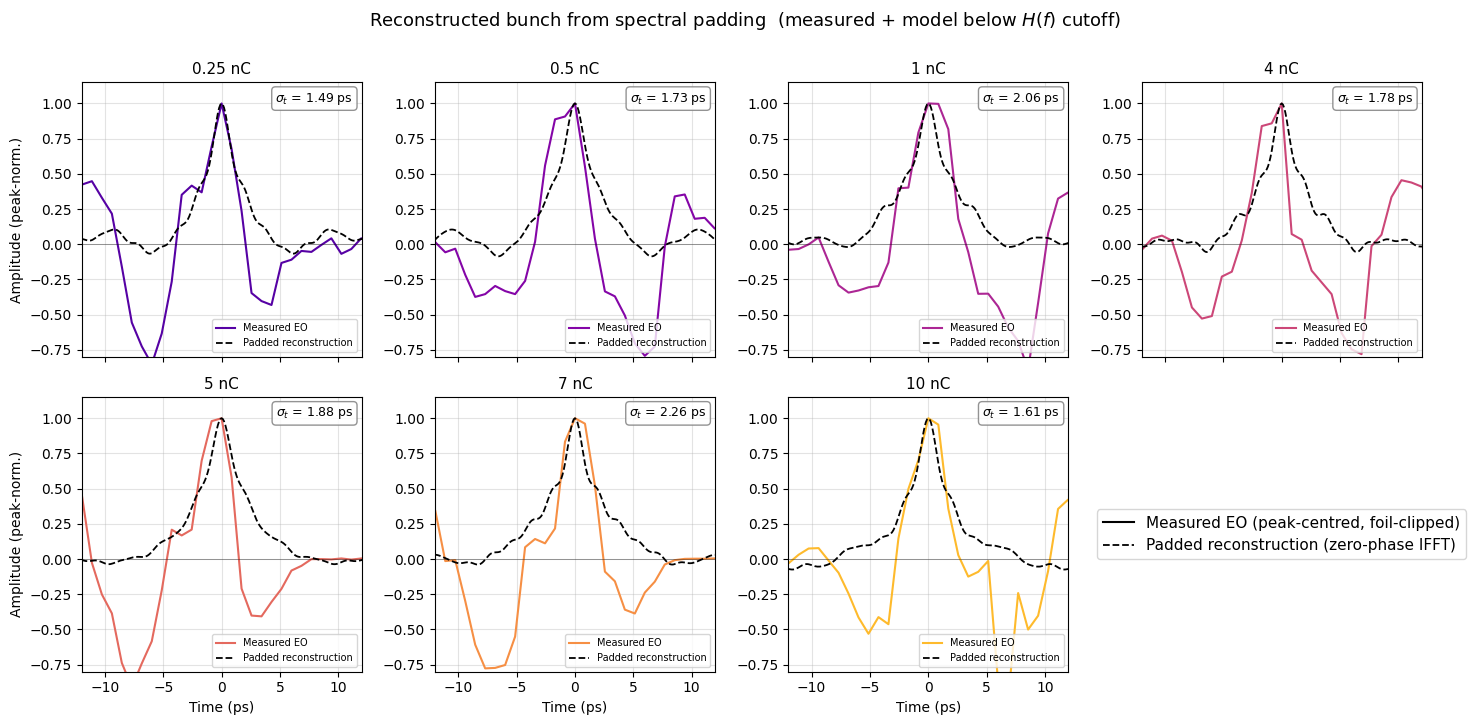

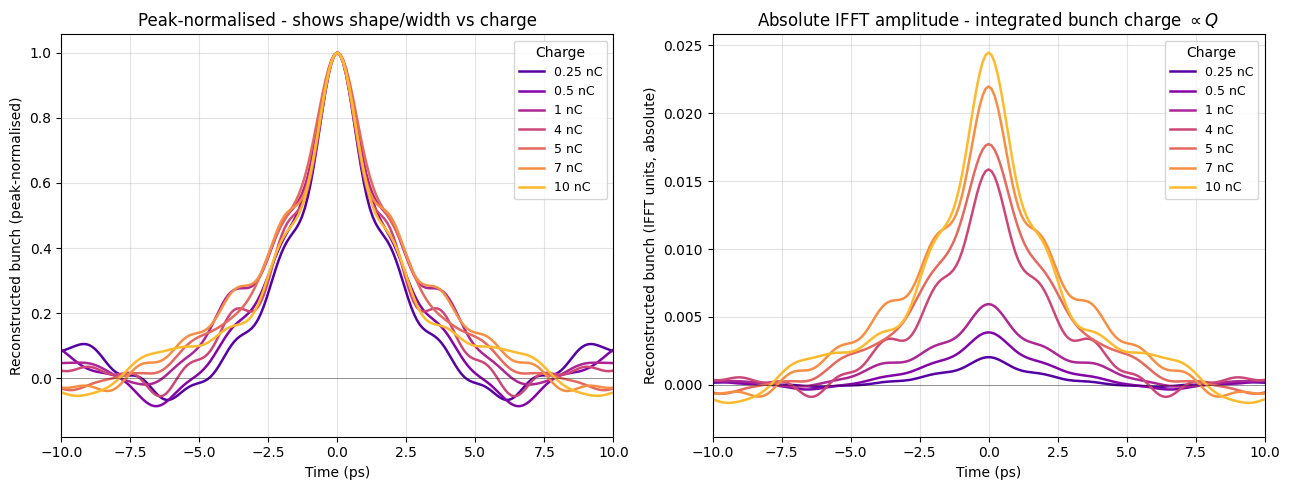

 Q (nC)    FWHM EO (ps)    FWHM padded (ps)   FWHM intrinsic (ps)
   0.25            2.56                2.53                  3.50
   0.50            3.60                2.98                  4.08
   1.00            3.63                3.63                  4.86
   4.00            2.78                3.18                  4.20
   5.00            3.03                3.63                  4.42
   7.00            3.06                3.81                  5.33
  10.00            3.21                2.84                  3.79


In [17]:
# ── Section 3e: magnitude-only spectral padding -> centred bunch profile ────
def hp_butter_local(f, fc, n):
    x = np.where(f > 0, (f/fc)**(2*n), 0.0)
    return np.sqrt(x / (1.0 + x))

PAD_FACTOR = 8          # zero-pad in frequency -> finer dt in the IFFT
WIN_KIND   = 'hann'     # window applied before FFT for consistency with Section 3c fit

eo_recon = []
for r, g in zip(results, gauss_fits):
    sig = r['sig']
    dp  = r['delay_ps']
    n   = len(sig)
    dt_ps = (dp[-1] - dp[0]) / (n - 1)
    win = np.hanning(n) if WIN_KIND == 'hann' else np.ones(n)

    # Measured spectrum magnitude on the native freq grid
    S_meas_mag = np.abs(np.fft.rfft(sig * win))
    f_GHz      = np.fft.rfftfreq(n, d=dt_ps*1e-12) / 1e9

    # Build the reconstructed magnitude on the same grid
    H_arr   = hp_butter_local(f_GHz, fc_fit, n_fit)
    S_fit   = g['A'] * np.exp(-0.5 * (f_GHz / g['sigma'])**2)
    S_recon = S_meas_mag + (1.0 - H_arr) * S_fit

    # Zero-pad the spectrum at the high-f end to get finer time resolution after IFFT
    n_out      = n * PAD_FACTOR
    rfft_len   = n_out // 2 + 1
    S_padded   = np.zeros(rfft_len)
    S_padded[:len(S_recon)] = S_recon

    # Inverse FFT: zero-phase spectrum -> real symmetric time function; centre with fftshift
    rho_recon  = np.fft.fftshift(np.fft.irfft(S_padded, n=n_out))
    dt_new     = dt_ps * n / n_out             # = 1/(2*fmax_native), unchanged by padding in freq
    t_recon    = (np.arange(n_out) - n_out//2) * dt_new

    # Also IFFT the measured-only spectrum the same way, for direct comparison
    S_meas_padded = np.zeros(rfft_len)
    S_meas_padded[:len(S_meas_mag)] = S_meas_mag
    rho_meas_mag = np.fft.fftshift(np.fft.irfft(S_meas_padded, n=n_out))

    eo_recon.append({
        'Q': r['Q'], 'label': g['label'],
        'sig': sig, 'dp': dp,
        't_recon': t_recon, 'rho_recon': rho_recon, 'rho_meas_mag': rho_meas_mag,
        'f_GHz': f_GHz, 'S_meas_mag': S_meas_mag, 'S_recon': S_recon,
        'H': H_arr, 'S_fit': S_fit,
        'sigma_t_ps': g['sigma_t_ps'],
    })

# ── Figure 1: spectrum patching for one representative charge (1 nC) ────────
ex = next(e for e in eo_recon if e['Q'] == 1.0)
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(ex['f_GHz'], ex['S_meas_mag'],          'C0-',  lw=1.4, label=r'$|Z_{\rm meas}(f)|$ (measured, foil-clipped)')
ax.plot(ex['f_GHz'], ex['S_recon'],             'C3--', lw=1.4, label=r'$|Z_{\rm recon}(f)|$ (after low-f padding)')
ax.plot(ex['f_GHz'], ex['S_fit'],               'k:',   lw=1.2, label=r'$S_{\rm fit}(f)$ (intrinsic Gaussian)')
ax.plot(ex['f_GHz'], (1 - ex['H']) * ex['S_fit'],'C2-.',lw=1.0, label=r'$(1-H)\,S_{\rm fit}$ (the added piece)')
ax.axvspan(0, F_CUT_GHZ, color='C3', alpha=0.10, label=f'<{F_CUT_GHZ:.0f} GHz (foil-clipped)')
ax.set_xlim(0, 400)
ax.set_xlabel('Frequency (GHz)')
ax.set_ylabel('Amplitude (a.u.)')
ax.set_title('Spectral padding illustrated for the 1 nC scan')
ax.legend(fontsize=9, loc='upper right')
ax.grid(True, alpha=0.35)
plt.tight_layout()
plt.savefig('Results/spectrum_padding_example.png', dpi=200, bbox_inches='tight')
plt.show()

# ── Figure 2: per-charge time-domain measured (centred) vs reconstruction ───
n_q   = len(eo_recon)
ncols = 4
nrows = int(np.ceil(n_q / ncols))
cols  = plt.cm.plasma(np.linspace(0.15, 0.85, n_q))

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.6*nrows), sharex=True)
axes = np.atleast_2d(axes).ravel()

for i, (e, col) in enumerate(zip(eo_recon, cols)):
    ax = axes[i]
    # Centre the measured EO on its positive peak for shape comparison
    sig = e['sig']
    dp  = e['dp']
    pk_idx = int(np.abs(sig).argmax())
    sign   = 1.0 if sig[pk_idx] > 0 else -1.0
    eo_n   = sign * sig / np.abs(sig).max()
    t_eo   = dp - dp[pk_idx]

    # Reconstruction: peak-normalised, already centred at t=0
    rho_n  = e['rho_recon'] / e['rho_recon'].max()

    ax.plot(t_eo,        eo_n,  color=col, lw=1.5, label='Measured EO')
    ax.plot(e['t_recon'], rho_n, color='k', lw=1.3, ls='--', label='Padded reconstruction')
    ax.axhline(0, color='k', lw=0.5, alpha=0.5)
    half = max(12.0, 4.5*e['sigma_t_ps'])
    ax.set_xlim(-half, half)
    ax.set_ylim(-0.8, 1.15)
    ax.set_title(e['label'], fontsize=11)
    ax.grid(True, alpha=0.35)
    ax.text(0.97, 0.97, fr"$\sigma_t$ = {e['sigma_t_ps']:.2f} ps",
            transform=ax.transAxes, ha='right', va='top', fontsize=9,
            bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='0.5', alpha=0.85))
    if i % ncols == 0:
        ax.set_ylabel('Amplitude (peak-norm.)')
    if i >= ncols*(nrows-1):
        ax.set_xlabel('Time (ps)')
    ax.legend(fontsize=7, loc='lower right')

for j in range(n_q, len(axes)):
    axes[j].set_visible(False)
if n_q < len(axes):
    leg_ax = axes[n_q]; leg_ax.set_visible(True); leg_ax.axis('off')
    leg_handles = [
        plt.Line2D([0],[0], color='k', lw=1.5, label='Measured EO (peak-centred, foil-clipped)'),
        plt.Line2D([0],[0], color='k', lw=1.3, ls='--', label='Padded reconstruction (zero-phase IFFT)'),
    ]
    leg_ax.legend(handles=leg_handles, loc='center', fontsize=11, frameon=True)

fig.suptitle('Reconstructed bunch from spectral padding  (measured + model below $H(f)$ cutoff)',
             fontsize=13, y=1.00)
plt.tight_layout()
plt.savefig('Results/bunch_lowf_padded_per_charge.png', dpi=200, bbox_inches='tight')
plt.show()

# ── Figure 3: padded reconstructions overlaid - normalised and absolute ────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
for e, col in zip(eo_recon, cols):
    norm = e['rho_recon'] / e['rho_recon'].max()
    ax1.plot(e['t_recon'], norm,             color=col, lw=1.8, label=e['label'])
    ax2.plot(e['t_recon'], e['rho_recon'],   color=col, lw=1.8, label=e['label'])

for ax in (ax1, ax2):
    ax.axhline(0, color='k', lw=0.5, alpha=0.5)
    ax.set_xlim(-10, 10)
    ax.set_xlabel('Time (ps)')
    ax.grid(True, alpha=0.35)
    ax.legend(title='Charge', fontsize=9, loc='upper right')
ax1.set_ylabel('Reconstructed bunch (peak-normalised)')
ax1.set_title('Peak-normalised - shows shape/width vs charge')
ax2.set_ylabel('Reconstructed bunch (IFFT units, absolute)')
ax2.set_title(r'Absolute IFFT amplitude - integrated bunch charge $\propto Q$')
plt.tight_layout()
plt.savefig('Results/bunch_lowf_padded_overlay.png', dpi=200, bbox_inches='tight')
plt.show()

# ── FWHM summary ────────────────────────────────────────────────────────────
def _fwhm_of_central(t, y):
    yy = np.where(np.isnan(y), -np.inf, y)
    if yy.max() <= 0: return float('nan')
    half = 0.5 * yy.max(); ipk = int(yy.argmax())
    left = yy[:ipk+1]
    lc = np.where(np.diff(np.sign(left - half)))[0]
    if len(lc) == 0: return float('nan')
    i = lc[-1]; tL = t[i] + (t[i+1]-t[i]) * (half - yy[i]) / (yy[i+1] - yy[i])
    right = yy[ipk:]
    rc = np.where(np.diff(np.sign(right - half)))[0]
    if len(rc) == 0: return float('nan')
    i = ipk + rc[0]; tR = t[i] + (t[i+1]-t[i]) * (half - yy[i]) / (yy[i+1] - yy[i])
    return tR - tL

print(f"{'Q (nC)':>7}  {'FWHM EO (ps)':>14}  {'FWHM padded (ps)':>18}  {'FWHM intrinsic (ps)':>20}")
for e in eo_recon:
    sig = e['sig']
    pk_idx = int(np.abs(sig).argmax())
    sign = 1.0 if sig[pk_idx] > 0 else -1.0
    eo_n = sign * sig / np.abs(sig).max()
    t_eo = e['dp'] - e['dp'][pk_idx]
    fwhm_eo  = _fwhm_of_central(t_eo, np.clip(eo_n, 0, None))
    fwhm_rec = _fwhm_of_central(e['t_recon'], np.clip(e['rho_recon']/e['rho_recon'].max(), 0, None))
    fwhm_int = 2.3548 * e['sigma_t_ps']
    print(f"{e['Q']:7.2f}  {fwhm_eo:14.2f}  {fwhm_rec:18.2f}  {fwhm_int:20.2f}")


## Section 3f: Forward Model — Reproducing the EO Dips from Gaussian × H(f)

Sections 3d and 3e went *backwards* — from the measured spectrum to a bunch profile. Here we go forwards: take the intrinsic Gaussian `S_fit(f) = A·exp(-f²/(2σ²))` (the bunch's natural form factor), multiply by the foil high-pass `H(f;f_c,n)`, IFFT, and check that the resulting time-domain pulse shows the same characteristic positive-peak-with-flanking-dips structure as the raw EO measurement.

If the model is self-consistent, the forward-IFFT pulse should reproduce the measured EO pulse's shape — both the central FWHM and the depth/location of the negative undershoots. That validates the whole modelling chain from Section 3b onwards.

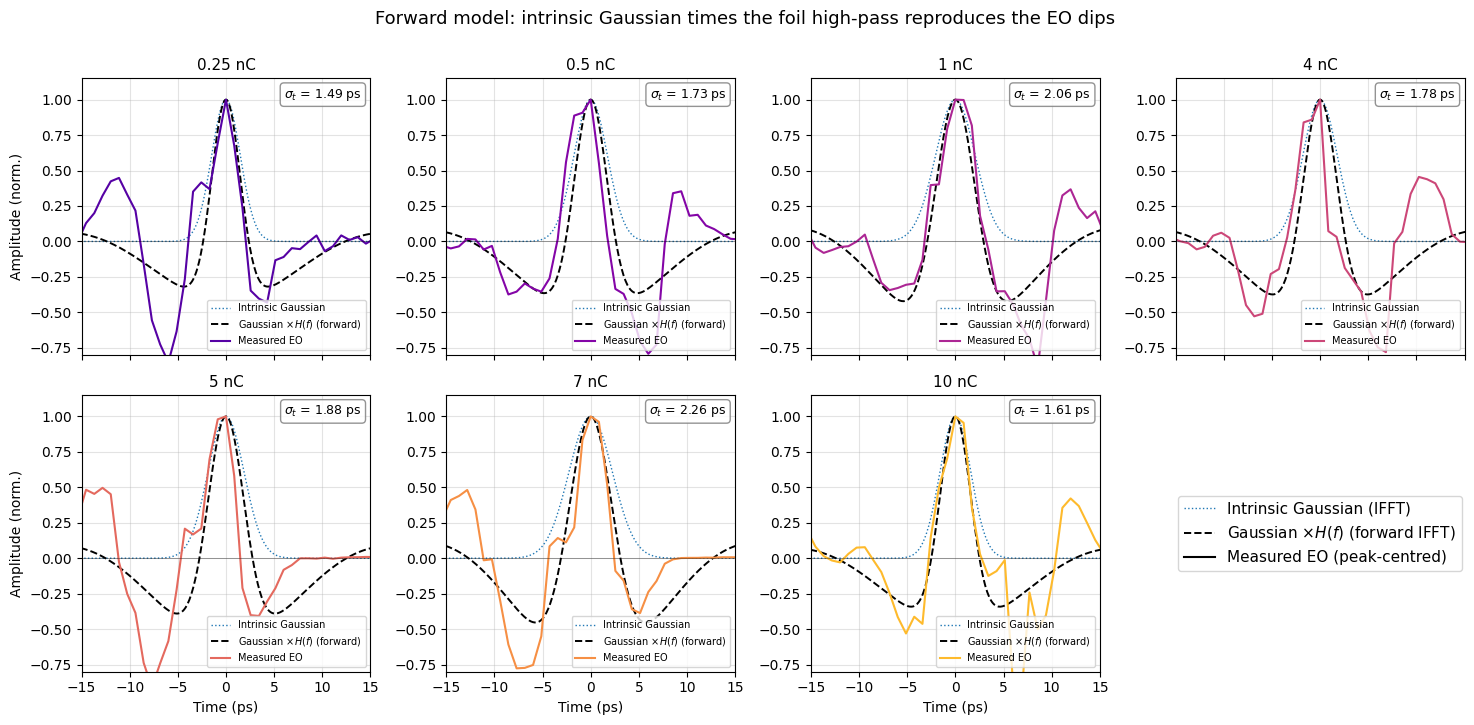

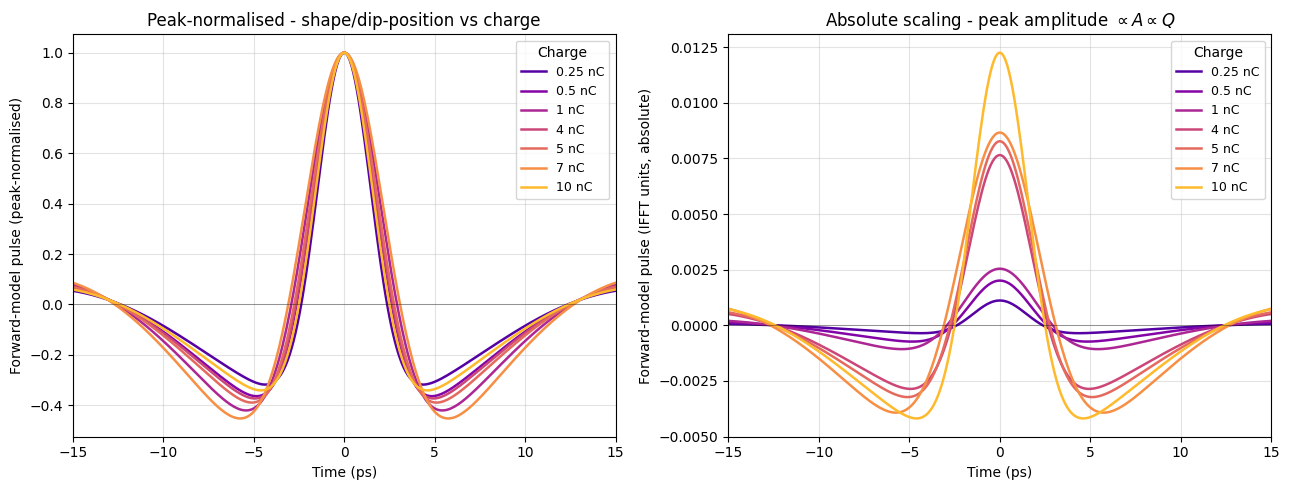

 Q (nC)    FWHM EO   FWHM fwd   dip EO/pk   dip fwd/pk
   0.25       2.56       2.80      -0.852       -0.318
   0.50       3.60       3.15      -0.792       -0.364
   1.00       3.63       3.57      -0.890       -0.421
   4.00       2.78       3.21      -0.780       -0.374
   5.00       3.03       3.34      -0.910       -0.390
   7.00       3.06       3.81      -0.776       -0.453
  10.00       3.21       2.97      -0.997       -0.342


In [18]:
# ── Section 3f: forward Gaussian * H(f) -> IFFT -> bipolar pulse ───────────
# Build a fine frequency grid, evaluate (intrinsic Gaussian) and (Gaussian * H)
# per charge, IFFT both with zero phase to centred real signals, and overlay
# on the measured EO pulse.

N_TIME = 4096
DT_PS  = 0.1
T_TOT  = N_TIME * DT_PS
DF_GHZ = 1e3 / T_TOT
F_FWD  = np.arange(N_TIME//2 + 1) * DF_GHZ
t_fwd  = (np.arange(N_TIME) - N_TIME//2) * DT_PS

H_fwd = hp_butter_local(F_FWD, fc_fit, n_fit)

forward_model = []
for g in gauss_fits:
    A, sig = g['A'], g['sigma']
    S_intrinsic = A * np.exp(-0.5 * (F_FWD/sig)**2)
    S_filtered  = S_intrinsic * H_fwd

    rho_intrinsic = np.fft.fftshift(np.fft.irfft(S_intrinsic, n=N_TIME))
    rho_filtered  = np.fft.fftshift(np.fft.irfft(S_filtered,  n=N_TIME))

    forward_model.append({
        'Q': g['Q'], 'label': g['label'],
        'sigma_t_ps': g['sigma_t_ps'],
        'rho_intrinsic': rho_intrinsic,
        'rho_filtered':  rho_filtered,
    })

# ── Per-charge subplots: intrinsic vs filtered vs measured EO ───────────────
n_q   = len(forward_model)
ncols = 4
nrows = int(np.ceil(n_q / ncols))
cols  = plt.cm.plasma(np.linspace(0.15, 0.85, n_q))

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.6*nrows), sharex=True)
axes = np.atleast_2d(axes).ravel()

for i, (fm, r, col) in enumerate(zip(forward_model, results, cols)):
    ax = axes[i]
    # Normalise forward model and intrinsic by the intrinsic peak
    norm_int = fm['rho_intrinsic'].max()
    rho_int_n = fm['rho_intrinsic'] / norm_int
    rho_fil_n = fm['rho_filtered']  / norm_int

    # Centre measured EO pulse on its absolute peak, normalise by its own positive peak
    sig    = r['sig']
    dp     = r['delay_ps']
    pk_idx = int(np.abs(sig).argmax())
    sign   = 1.0 if sig[pk_idx] > 0 else -1.0
    eo_n   = sign * sig
    eo_n   = eo_n / max(eo_n.max(), 1e-12)
    t_eo   = dp - dp[pk_idx]
    # Also normalise the filtered model so its positive peak = 1, for shape comparison with EO
    rho_fil_for_eo = fm['rho_filtered'] / max(fm['rho_filtered'].max(), 1e-12)

    ax.plot(t_fwd, rho_int_n,      color='C0', lw=1.0, ls=':',  label='Intrinsic Gaussian')
    ax.plot(t_fwd, rho_fil_for_eo, color='k',  lw=1.4, ls='--', label=r'Gaussian $\times H(f)$ (forward)')
    ax.plot(t_eo,  eo_n,           color=col, lw=1.5,            label='Measured EO')
    ax.axhline(0, color='k', lw=0.5, alpha=0.5)
    half = max(15.0, 5*fm['sigma_t_ps'])
    ax.set_xlim(-half, half)
    ax.set_ylim(-0.8, 1.15)
    ax.set_title(fm['label'], fontsize=11)
    ax.grid(True, alpha=0.35)
    ax.text(0.97, 0.97, fr"$\sigma_t$ = {fm['sigma_t_ps']:.2f} ps",
            transform=ax.transAxes, ha='right', va='top', fontsize=9,
            bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='0.5', alpha=0.85))
    if i % ncols == 0:
        ax.set_ylabel('Amplitude (norm.)')
    if i >= ncols*(nrows-1):
        ax.set_xlabel('Time (ps)')
    ax.legend(fontsize=7, loc='lower right')

for j in range(n_q, len(axes)):
    axes[j].set_visible(False)
if n_q < len(axes):
    leg_ax = axes[n_q]; leg_ax.set_visible(True); leg_ax.axis('off')
    leg_handles = [
        plt.Line2D([0],[0], color='C0', lw=1.0, ls=':',  label='Intrinsic Gaussian (IFFT)'),
        plt.Line2D([0],[0], color='k',  lw=1.4, ls='--', label=r'Gaussian $\times H(f)$ (forward IFFT)'),
        plt.Line2D([0],[0], color='k',  lw=1.5,           label='Measured EO (peak-centred)'),
    ]
    leg_ax.legend(handles=leg_handles, loc='center', fontsize=11, frameon=True)

fig.suptitle('Forward model: intrinsic Gaussian times the foil high-pass reproduces the EO dips',
             fontsize=13, y=1.00)
plt.tight_layout()
plt.savefig('Results/forward_model_eo_dips.png', dpi=200, bbox_inches='tight')
plt.show()

# ── Overlay of all forward-model filtered pulses (normalised + absolute) ────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
for fm, col in zip(forward_model, cols):
    norm = fm['rho_filtered'] / max(fm['rho_filtered'].max(), 1e-12)
    ax1.plot(t_fwd, norm,                 color=col, lw=1.8, label=fm['label'])
    ax2.plot(t_fwd, fm['rho_filtered'],   color=col, lw=1.8, label=fm['label'])
for ax in (ax1, ax2):
    ax.axhline(0, color='k', lw=0.5, alpha=0.5)
    ax.set_xlim(-15, 15)
    ax.set_xlabel('Time (ps)')
    ax.grid(True, alpha=0.35)
    ax.legend(title='Charge', fontsize=9, loc='upper right')
ax1.set_ylabel('Forward-model pulse (peak-normalised)')
ax1.set_title('Peak-normalised - shape/dip-position vs charge')
ax2.set_ylabel('Forward-model pulse (IFFT units, absolute)')
ax2.set_title(r'Absolute scaling - peak amplitude $\propto A \propto Q$')
plt.tight_layout()
plt.savefig('Results/forward_model_overlay.png', dpi=200, bbox_inches='tight')
plt.show()

# ── Quantitative comparison of dip depth and FWHM ───────────────────────────
def _fwhm_central(t, y):
    yy = np.where(np.isnan(y), -np.inf, y)
    if yy.max() <= 0: return float('nan')
    half = 0.5 * yy.max(); ipk = int(yy.argmax())
    left = yy[:ipk+1]
    lc = np.where(np.diff(np.sign(left - half)))[0]
    if len(lc) == 0: return float('nan')
    i = lc[-1]; tL = t[i] + (t[i+1]-t[i]) * (half - yy[i]) / (yy[i+1] - yy[i])
    right = yy[ipk:]
    rc = np.where(np.diff(np.sign(right - half)))[0]
    if len(rc) == 0: return float('nan')
    i = ipk + rc[0]; tR = t[i] + (t[i+1]-t[i]) * (half - yy[i]) / (yy[i+1] - yy[i])
    return tR - tL

print(f"{'Q (nC)':>7}  {'FWHM EO':>9}  {'FWHM fwd':>9}  {'dip EO/pk':>10}  {'dip fwd/pk':>11}")
for fm, r in zip(forward_model, results):
    sig = r['sig']; pk_idx = int(np.abs(sig).argmax())
    sign = 1.0 if sig[pk_idx] > 0 else -1.0
    eo_n = sign * sig / max(np.abs(sig).max(), 1e-12)
    t_eo = r['delay_ps'] - r['delay_ps'][pk_idx]
    fwhm_eo  = _fwhm_central(t_eo, np.clip(eo_n, 0, None))

    rho_f = fm['rho_filtered'] / max(fm['rho_filtered'].max(), 1e-12)
    fwhm_f = _fwhm_central(t_fwd, np.clip(rho_f, 0, None))

    dip_eo  = float(eo_n.min())                          # most negative excursion (normalised, so 0..-1)
    dip_fwd = float(rho_f.min())
    print(f"{fm['Q']:7.2f}  {fwhm_eo:9.2f}  {fwhm_f:9.2f}  {dip_eo:10.3f}  {dip_fwd:11.3f}")


## Section 4: High-Frequency Falloff vs Charge

The centroid and `<50 GHz` power-fraction metrics in earlier sections are confounded by the **geometric low-frequency cutoff** of the CTR collection optics. At high charge the bunch radiates a true long-wavelength tail, but the finite target/aperture clips it, so the observed low-frequency amplitude is suppressed by an *instrumental* effect on top of the real bunch-length shift. Any metric that integrates power across the full band, or normalises to total power, mixes these two effects together.

To isolate the bunch-length effect on the high-frequency tail, this section uses metrics that are robust to the geometric low-f clipping:

1. **Mid-band-normalised spectra.** Each spectrum is divided by its peak amplitude in 30–100 GHz, the CTR band that is always populated. This makes shapes directly comparable.
2. **$f_{50}$ — half-amplitude rolloff frequency.** Lowest frequency *above the peak* where the smoothed amplitude crosses 50% of the peak. Directly probes the high-f shoulder.
3. **Half-bandwidth $\Delta f_{1/2} = f_{50} - f_{\rm peak}$.** Subtracts off any drift in the peak position (which itself shifts down with charge as the long-wavelength side recovers from clipping less aggressively at higher charge). The remaining width is the pure high-side spectral extent.
4. **Per-nC absolute high-band amplitude $A_{\rm HF}/Q$.** Mean $|S(f)|$ over 150–350 GHz divided by nominal charge, in raw mV units (no normalisation). A coherent bunch radiates proportional to $Q$; if every shot were the same bunch shape, $A_{\rm HF}/Q$ would be constant. A *decrease* with charge therefore directly quantifies loss of high-f coherence due to space-charge bunch lengthening.

Then the analysis **zooms on 0.25, 0.5, 1 nC** — the regime where the bunch is shortest and the high-f tail is least suppressed by space-charge effects — to establish the cleanest reference for what the system can resolve.

Expected trend (all four metrics): higher charge → space-charge bunch lengthening → $f_{50}$ down, $\Delta f_{1/2}$ down, $A_{\rm HF}/Q$ down.


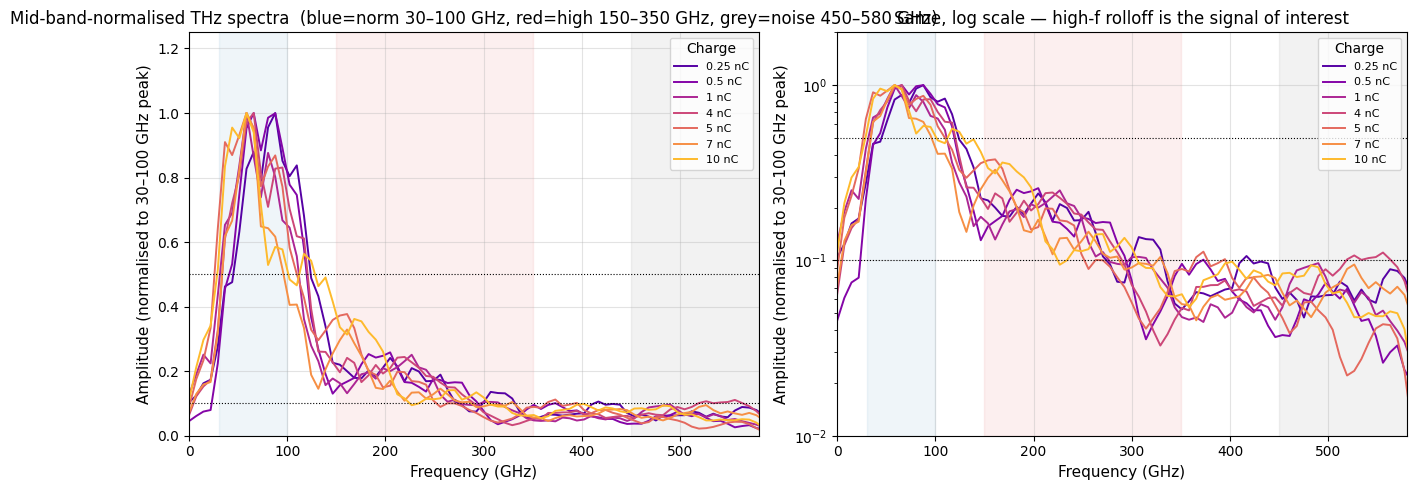

 Q (nC)   f_peak    f_50    f_10     Δf½   A_HF abs (mV)   A_HF/Q (mV/nC)
   0.25     87.7   124.3   277.9    36.6           4.599           18.398
   0.50     65.8   124.3   299.8    58.5          11.411           22.823
   1.00     58.5   117.0   277.9    58.5          13.239           13.239
   4.00     65.8   124.3   292.5    58.5          29.836            7.459
   5.00     58.5   117.0   255.9    58.5          51.424           10.285
   7.00     58.5   102.4   292.5    43.9          53.424            7.632
  10.00     58.5   102.4   226.7    43.9          60.368            6.037


In [19]:
# ── High-frequency falloff: peak-band-normalised spectra and rolloff metrics ──
MID_BAND_GHZ  = (30.0, 100.0)   # CTR peak band — always populated, used for normalisation
HIGH_BAND_GHZ = (150.0, 350.0)  # high-f tail — above the peak, below the noise-floor regime
NOISE_BAND_GHZ= (450.0, 580.0)  # near Nyquist — used as a noise floor estimate
SMOOTH_BINS   = 5               # boxcar smoothing for rolloff estimation (~35 GHz)

def smooth(y, w):
    if w <= 1: return y.copy()
    k = np.ones(w)/w
    return np.convolve(y, k, mode='same')

def band_idx(f, lo, hi):
    return (f >= lo) & (f <= hi)

metrics = []
for sp in spectra:
    f, S = sp['freq_GHz'], sp['spec'].copy()
    Ss   = smooth(S, SMOOTH_BINS)
    midm = band_idx(f, *MID_BAND_GHZ)
    hi_m = band_idx(f, *HIGH_BAND_GHZ)
    nzm  = band_idx(f, *NOISE_BAND_GHZ)

    # Noise floor estimate (median |S| at near-Nyquist frequencies)
    noise_floor = float(np.median(S[nzm])) if nzm.any() else 0.0

    peak_amp = Ss[midm].max()
    peak_idx = np.where(midm)[0][Ss[midm].argmax()]
    peak_f   = f[peak_idx]
    Sn       = Ss / peak_amp

    # f_50 / f_10: first crossing above the peak
    def first_cross(level):
        cand = np.where((np.arange(len(Sn)) > peak_idx) & (Sn < level))[0]
        return f[cand[0]] if len(cand) else np.nan
    f_50 = first_cross(0.5)
    f_10 = first_cross(0.1)
    hbw  = f_50 - peak_f if np.isfinite(f_50) else np.nan

    # Absolute high-band amplitude, noise-subtracted, normalised per nC
    A_HF_abs = float(np.mean(np.clip(S[hi_m] - noise_floor, 0.0, None)))  # mV-equivalent
    A_HF_perQ = A_HF_abs / sp['Q']

    metrics.append({
        'label': sp['label'], 'Q': sp['Q'],
        'f': f, 'Sn': Sn,
        'peak_f': peak_f, 'peak_amp': peak_amp, 'noise': noise_floor,
        'f_50': f_50, 'f_10': f_10, 'hbw': hbw,
        'A_HF_abs': A_HF_abs, 'A_HF_perQ': A_HF_perQ,
    })

# Plot: mid-band-normalised spectra overlaid (linear + log) with bands shaded
fig, (axL, axR) = plt.subplots(1, 2, figsize=(13, 5))
for m, col in zip(metrics, colors):
    axL.plot(m['f'], m['Sn'], color=col, lw=1.4, label=m['label'])
    axR.semilogy(m['f'], np.clip(m['Sn'], 1e-3, None), color=col, lw=1.4, label=m['label'])

for ax in (axL, axR):
    ax.axvspan(*MID_BAND_GHZ,  color='C0', alpha=0.07)
    ax.axvspan(*HIGH_BAND_GHZ, color='C3', alpha=0.07)
    ax.axvspan(*NOISE_BAND_GHZ,color='0.5', alpha=0.10)
    ax.set_xlim(0, 580)
    ax.set_xlabel('Frequency (GHz)', fontsize=11)
    ax.set_ylabel('Amplitude (normalised to 30–100 GHz peak)', fontsize=11)
    ax.grid(True, alpha=0.35)
    ax.legend(title='Charge', fontsize=8, loc='upper right')
axL.set_ylim(0, 1.25)
axL.axhline(0.5, color='k', ls=':', lw=0.8); axL.axhline(0.1, color='k', ls=':', lw=0.8)
axR.set_ylim(1e-2, 2)
axR.axhline(0.5, color='k', ls=':', lw=0.8); axR.axhline(0.1, color='k', ls=':', lw=0.8)
axL.set_title('Mid-band-normalised THz spectra  (blue=norm 30–100 GHz, red=high 150–350 GHz, grey=noise 450–580 GHz)')
axR.set_title('Same, log scale — high-f rolloff is the signal of interest')
plt.tight_layout()
plt.savefig('Results/spectra_midband_normalised.png', dpi=200, bbox_inches='tight')
plt.show()

print(f"{'Q (nC)':>7}  {'f_peak':>7}  {'f_50':>6}  {'f_10':>6}  {'Δf½':>6}  {'A_HF abs (mV)':>14}  {'A_HF/Q (mV/nC)':>15}")
for m in metrics:
    print(f"{m['Q']:7.2f}  {m['peak_f']:7.1f}  {m['f_50']:6.1f}  {m['f_10']:6.1f}  {m['hbw']:6.1f}  "
          f"{1e3*m['A_HF_abs']:14.3f}  {1e3*m['A_HF_perQ']:15.3f}")


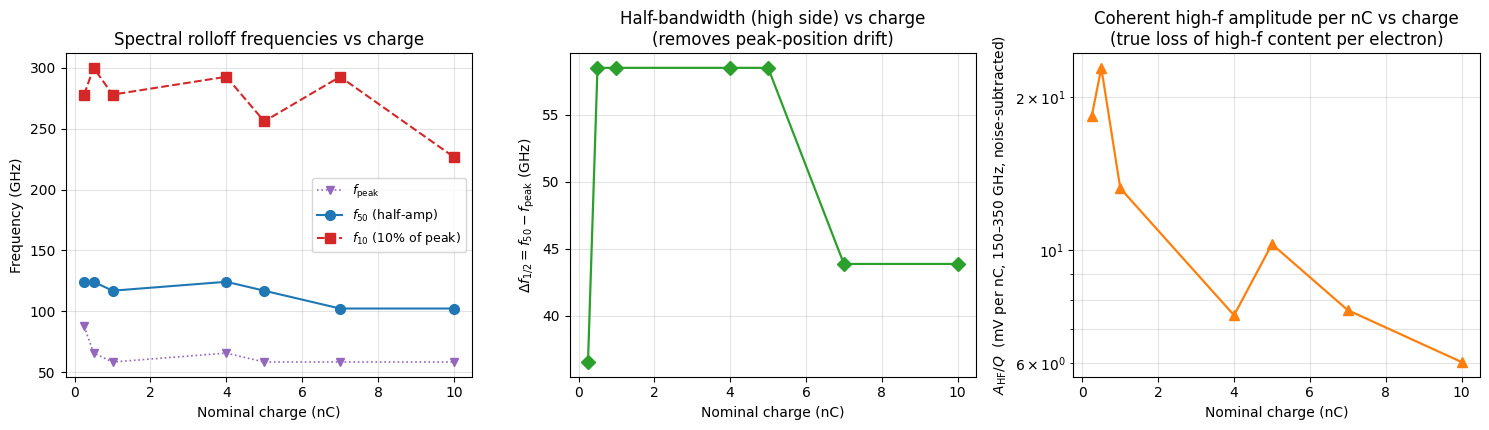

In [20]:
# ── Rolloff metrics vs charge ────────────────────────────────────────────────
Q_arr    = np.array([m['Q']    for m in metrics])
pf_arr   = np.array([m['peak_f'] for m in metrics])
f50_arr  = np.array([m['f_50'] for m in metrics])
f10_arr  = np.array([m['f_10'] for m in metrics])
hbw_arr  = np.array([m['hbw']  for m in metrics])
AHFq_arr = np.array([m['A_HF_perQ'] for m in metrics]) * 1e3  # mV/nC

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

axes[0].plot(Q_arr, pf_arr,  'C4v:',  lw=1.2, ms=6, label=r'$f_{\rm peak}$')
axes[0].plot(Q_arr, f50_arr, 'C0o-',  lw=1.5, ms=7, label=r'$f_{50}$ (half-amp)')
axes[0].plot(Q_arr, f10_arr, 'C3s--', lw=1.5, ms=7, label=r'$f_{10}$ (10% of peak)')
axes[0].set_xlabel('Nominal charge (nC)')
axes[0].set_ylabel('Frequency (GHz)')
axes[0].set_title('Spectral rolloff frequencies vs charge')
axes[0].legend(fontsize=9); axes[0].grid(True, alpha=0.35)

axes[1].plot(Q_arr, hbw_arr, 'C2D-', lw=1.6, ms=7)
axes[1].set_xlabel('Nominal charge (nC)')
axes[1].set_ylabel(r'$\Delta f_{1/2} = f_{50} - f_{\rm peak}$ (GHz)')
axes[1].set_title('Half-bandwidth (high side) vs charge\n(removes peak-position drift)')
axes[1].grid(True, alpha=0.35)

axes[2].semilogy(Q_arr, AHFq_arr, 'C1^-', lw=1.6, ms=7)
axes[2].set_xlabel('Nominal charge (nC)')
axes[2].set_ylabel(r'$A_{\rm HF}/Q$  (mV per nC, 150–350 GHz, noise-subtracted)')
axes[2].set_title('Coherent high-f amplitude per nC vs charge\n(true loss of high-f content per electron)')
axes[2].grid(True, alpha=0.35, which='both')

plt.tight_layout()
plt.savefig('Results/highfreq_falloff_vs_charge.png', dpi=200, bbox_inches='tight')
plt.show()


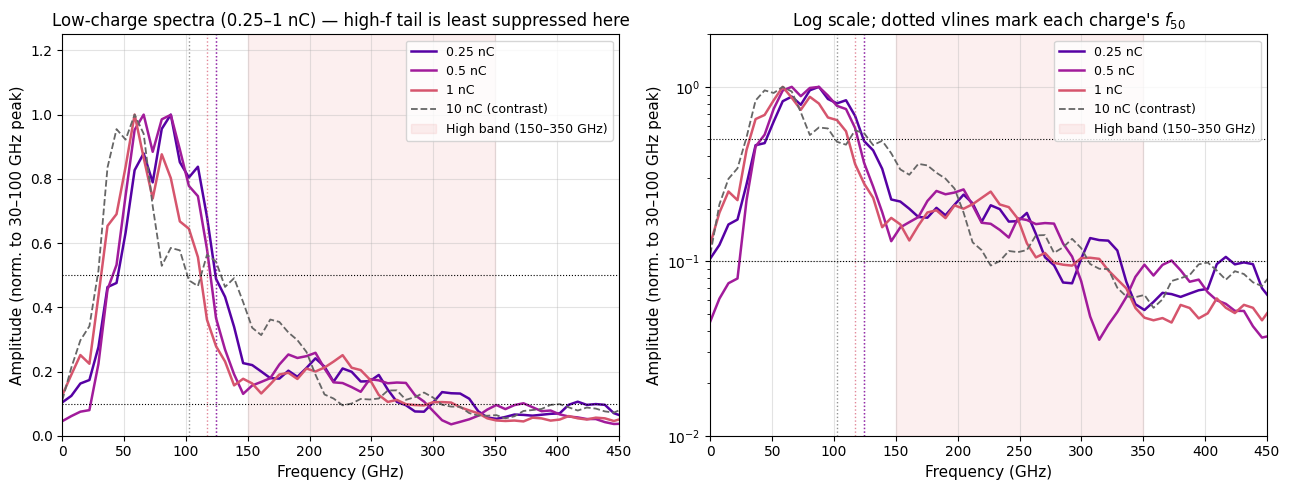

Low-charge group — cleanest indicator of intrinsic high-f response:
       Q   f_peak     f_50      Δf½   A_HF/Q (mV/nC)
    0.25     87.7    124.3     36.6       18.398
    0.50     65.8    124.3     58.5       22.823
    1.00     58.5    117.0     58.5       13.239

Reference (10 nC, space-charge-lengthened):
   10.00     58.5    102.4     43.9        6.037

Headline result:
  Mean f_50 (≤1 nC):   121.9 GHz
  f_50 at 10 nC:       102.4 GHz   →  rolloff falls by 19 GHz (16%)
  A_HF/Q ratio 0.25 nC / 10 nC: 3.0×  (per-electron high-f coherence loss from space-charge bunch lengthening)


In [21]:
# ── Low-charge zoom: cleanest high-f content (least space-charge lengthening) ─
LOW_Q = [0.25, 0.5, 1.0]
low_metrics = [m for m in metrics if m['Q'] in LOW_Q]
low_colors  = plt.cm.plasma(np.linspace(0.15, 0.55, len(low_metrics)))

fig, (axL, axR) = plt.subplots(1, 2, figsize=(13, 5))

for m, col in zip(low_metrics, low_colors):
    axL.plot(m['f'], m['Sn'], color=col, lw=1.8, label=m['label'])
    axR.semilogy(m['f'], np.clip(m['Sn'], 1e-3, None), color=col, lw=1.8, label=m['label'])
    if np.isfinite(m['f_50']):
        axL.axvline(m['f_50'], color=col, ls=':', lw=1.0, alpha=0.7)
        axR.axvline(m['f_50'], color=col, ls=':', lw=1.0, alpha=0.7)

# Overlay highest-charge spectrum (10 nC) for contrast
hi_m = next(m for m in metrics if m['Q'] == 10.0)
axL.plot(hi_m['f'], hi_m['Sn'], color='0.4', lw=1.3, ls='--', label='10 nC (contrast)')
axR.semilogy(hi_m['f'], np.clip(hi_m['Sn'], 1e-3, None), color='0.4', lw=1.3, ls='--', label='10 nC (contrast)')
if np.isfinite(hi_m['f_50']):
    axL.axvline(hi_m['f_50'], color='0.4', ls=':', lw=1.0, alpha=0.7)
    axR.axvline(hi_m['f_50'], color='0.4', ls=':', lw=1.0, alpha=0.7)

for ax in (axL, axR):
    ax.axvspan(*HIGH_BAND_GHZ, color='C3', alpha=0.07, label='High band (150–350 GHz)')
    ax.set_xlim(0, 450)
    ax.set_xlabel('Frequency (GHz)', fontsize=11)
    ax.set_ylabel('Amplitude (norm. to 30–100 GHz peak)', fontsize=11)
    ax.grid(True, alpha=0.35); ax.legend(fontsize=9, loc='upper right')
axL.set_ylim(0, 1.25)
axR.set_ylim(1e-2, 2)
axL.axhline(0.5, color='k', ls=':', lw=0.8); axL.axhline(0.1, color='k', ls=':', lw=0.8)
axR.axhline(0.5, color='k', ls=':', lw=0.8); axR.axhline(0.1, color='k', ls=':', lw=0.8)
axL.set_title('Low-charge spectra (0.25–1 nC) — high-f tail is least suppressed here')
axR.set_title(r"Log scale; dotted vlines mark each charge's $f_{50}$")

plt.tight_layout()
plt.savefig('Results/low_charge_highf_zoom.png', dpi=200, bbox_inches='tight')
plt.show()

# Summary print
def fmt(m):
    return (f"  {m['Q']:6.2f}  {m['peak_f']:7.1f}  {m['f_50']:7.1f}  {m['hbw']:7.1f}  "
            f"{1e3*m['A_HF_perQ']:11.3f}")

print('Low-charge group — cleanest indicator of intrinsic high-f response:')
print(f"  {'Q':>6}  {'f_peak':>7}  {'f_50':>7}  {'Δf½':>7}  {'A_HF/Q (mV/nC)':>15}")
for m in low_metrics:
    print(fmt(m))
print('\nReference (10 nC, space-charge-lengthened):')
print(fmt(hi_m))

# Headline numbers
f50_low  = np.nanmean([m['f_50'] for m in low_metrics])
f50_high = hi_m['f_50']
ratio    = (low_metrics[0]['A_HF_perQ']) / (hi_m['A_HF_perQ']) if hi_m['A_HF_perQ'] > 0 else np.nan
print(f"\nHeadline result:")
print(f"  Mean f_50 (≤1 nC):   {f50_low:5.1f} GHz")
print(f"  f_50 at 10 nC:       {f50_high:5.1f} GHz   →  rolloff falls by {f50_low - f50_high:.0f} GHz ({100*(f50_low-f50_high)/f50_low:.0f}%)")
print(f"  A_HF/Q ratio 0.25 nC / 10 nC: {ratio:.1f}×  (per-electron high-f coherence loss from space-charge bunch lengthening)")


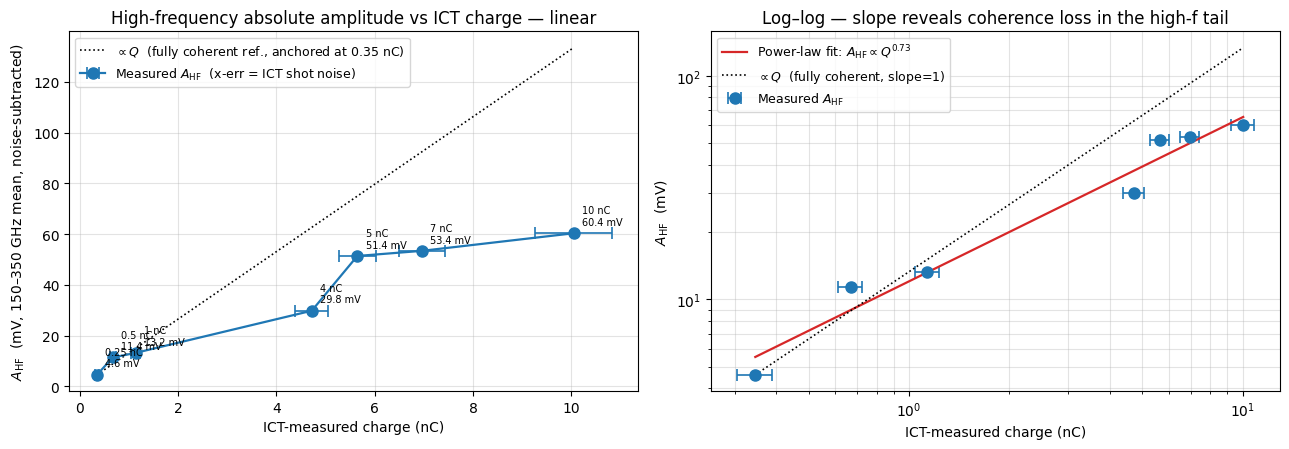

   Label    Q_nom    Q_ICT   shot σ    vs nom   A_HF (mV)
 0.25 nC     0.25    0.346    0.042    +38.5%       4.599
  0.5 nC     0.50    0.668    0.057    +33.6%      11.411
    1 nC     1.00    1.136    0.091    +13.6%      13.239
    4 nC     4.00    4.718    0.339    +18.0%      29.836
    5 nC     5.00    5.646    0.381    +12.9%      51.424
    7 nC     7.00    6.952    0.468     -0.7%      53.424
   10 nC    10.00   10.047    0.788     +0.5%      60.368

Power-law slope (log–log fit vs ICT charge):  A_HF ∝ Q^0.73
  (slope=1 → fully coherent;  slope<1 → progressive coherence loss with charge)
  A_HF(highest Q) / A_HF(lowest Q) = 13.1×   (would be 29.0× if perfectly coherent)
  → per-electron high-f efficiency at 10.0 nC is 0.45× that at 0.35 nC


In [22]:
# ── A_HF absolute amplitude across all charge tests (vs ICT-measured charge) ──
# A_HF_abs is the mean |S(f)| in 150–350 GHz with the near-Nyquist noise floor
# subtracted (computed in the Section 4 cell). It is the raw spectral amplitude
# in the high-frequency tail — NOT normalised to charge — so it answers
# "how much high-f signal did we actually detect?"
#
# The x-axis is the ICT-MEASURED bunch charge, not the operator-set nominal
# value. ICT charge follows the same physical relation used in
# ICT_Charge_Calibration.ipynb:
#       Q [nC] = 0.8 × |Σ V_n| × dt_eff,    dt_eff = 0.444 ns/sample
# with per-shot baseline from samples [0:700] and [1300:end] of the ICT trace.

ICT_BL_PRE  = slice(None, 700)
ICT_BL_POST = slice(1300, None)
ICT_DT_EFF  = 0.444  # ns/sample (calibrated against nominal Q in ICT notebook)

def ict_charge_nC(path):
    """Mean ICT charge across all steps/shots, with per-step uncertainties."""
    d   = np.load(path)
    ict = d['ictwf']  # (steps, 10, 2502)
    bl  = np.concatenate([ict[:, :, ICT_BL_PRE],
                          ict[:, :, ICT_BL_POST]], axis=2).mean(axis=2)  # (steps, 10)
    ict_c = ict - bl[:, :, np.newaxis]
    Q_shot = -ict_c.sum(axis=2) * 0.8 * ICT_DT_EFF   # (steps, 10) nC; pulse is negative
    Q_step = Q_shot.mean(axis=1)
    return Q_step.mean(), Q_shot.std(axis=1).mean(), Q_step.std()  # mean, shot σ, drift σ

# Compute ICT charge for each scan (SCANS ordering matches metrics[])
Q_ict_arr   = np.zeros(len(metrics))
Q_ict_shot  = np.zeros(len(metrics))  # within-step shot noise (1σ, nC)
Q_ict_drift = np.zeros(len(metrics))  # across-step phase-transport drift (1σ, nC)
Q_nom_arr   = np.array([m['Q'] for m in metrics])
for i, scan in enumerate(SCANS):
    Q_ict_arr[i], Q_ict_shot[i], Q_ict_drift[i] = ict_charge_nC(scan['path'])

AHF_arr = np.array([m['A_HF_abs'] for m in metrics]) * 1e3  # → mV-equivalent

# Power-law fit on log-log for trend reference (using ICT charge)
slope, intercept = np.polyfit(np.log(Q_ict_arr), np.log(AHF_arr), 1)
Q_fit   = np.linspace(Q_ict_arr.min(), Q_ict_arr.max(), 200)
AHF_pl  = np.exp(intercept) * Q_fit**slope
AHF_lin = AHF_arr[0] * (Q_fit / Q_ict_arr[0])  # ideal coherent A_HF ∝ Q, anchored at lowest Q

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

# (a) Linear
ax = axes[0]
ax.errorbar(Q_ict_arr, AHF_arr, xerr=Q_ict_shot,
            fmt='C0o-', lw=1.6, ms=8, capsize=4, capthick=1.2, elinewidth=1.2,
            label=r'Measured $A_{\rm HF}$  (x-err = ICT shot noise)')
ax.plot(Q_fit, AHF_lin, 'k:', lw=1.2,
        label=fr'$\propto Q$  (fully coherent ref., anchored at {Q_ict_arr[0]:.2f} nC)')
for Q, A, lbl in zip(Q_ict_arr, AHF_arr, [m['label'] for m in metrics]):
    ax.annotate(f'{lbl}\n{A:.1f} mV', (Q, A),
                textcoords='offset points', xytext=(6, 6), fontsize=7)
ax.set_xlabel('ICT-measured charge (nC)')
ax.set_ylabel(r'$A_{\rm HF}$  (mV, 150–350 GHz mean, noise-subtracted)')
ax.set_title('High-frequency absolute amplitude vs ICT charge — linear')
ax.legend(fontsize=9); ax.grid(True, alpha=0.35)

# (b) Log-log with power-law fit and Q^1 reference
ax = axes[1]
ax.errorbar(Q_ict_arr, AHF_arr, xerr=Q_ict_shot,
            fmt='C0o', ms=8, capsize=4, capthick=1.2, elinewidth=1.2,
            label=r'Measured $A_{\rm HF}$')
ax.plot(Q_fit, AHF_pl, 'C3-', lw=1.6,
        label=fr'Power-law fit: $A_{{\rm HF}} \propto Q^{{{slope:.2f}}}$')
ax.plot(Q_fit, AHF_lin, 'k:', lw=1.2, label=r'$\propto Q$  (fully coherent, slope=1)')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('ICT-measured charge (nC)')
ax.set_ylabel(r'$A_{\rm HF}$  (mV)')
ax.set_title('Log–log — slope reveals coherence loss in the high-f tail')
ax.legend(fontsize=9); ax.grid(True, alpha=0.35, which='both')

plt.tight_layout()
plt.savefig('Results/A_HF_abs_vs_charge.png', dpi=200, bbox_inches='tight')
plt.show()

print(f"{'Label':>8}  {'Q_nom':>7}  {'Q_ICT':>7}  {'shot σ':>7}  {'vs nom':>8}  {'A_HF (mV)':>10}")
for m, Qn, Qi, Qs, A in zip(metrics, Q_nom_arr, Q_ict_arr, Q_ict_shot, AHF_arr):
    dev = 100*(Qi-Qn)/Qn
    print(f"{m['label']:>8}  {Qn:7.2f}  {Qi:7.3f}  {Qs:7.3f}  {dev:+7.1f}%  {A:10.3f}")
print(f"\nPower-law slope (log–log fit vs ICT charge):  A_HF ∝ Q^{slope:.2f}")
print(f"  (slope=1 → fully coherent;  slope<1 → progressive coherence loss with charge)")
print(f"  A_HF(highest Q) / A_HF(lowest Q) = {AHF_arr[-1]/AHF_arr[0]:.1f}×   "
      f"(would be {Q_ict_arr[-1]/Q_ict_arr[0]:.1f}× if perfectly coherent)")
print(f"  → per-electron high-f efficiency at {Q_ict_arr[-1]:.1f} nC is "
      f"{(AHF_arr[-1]/AHF_arr[0])/(Q_ict_arr[-1]/Q_ict_arr[0]):.2f}× that at {Q_ict_arr[0]:.2f} nC")

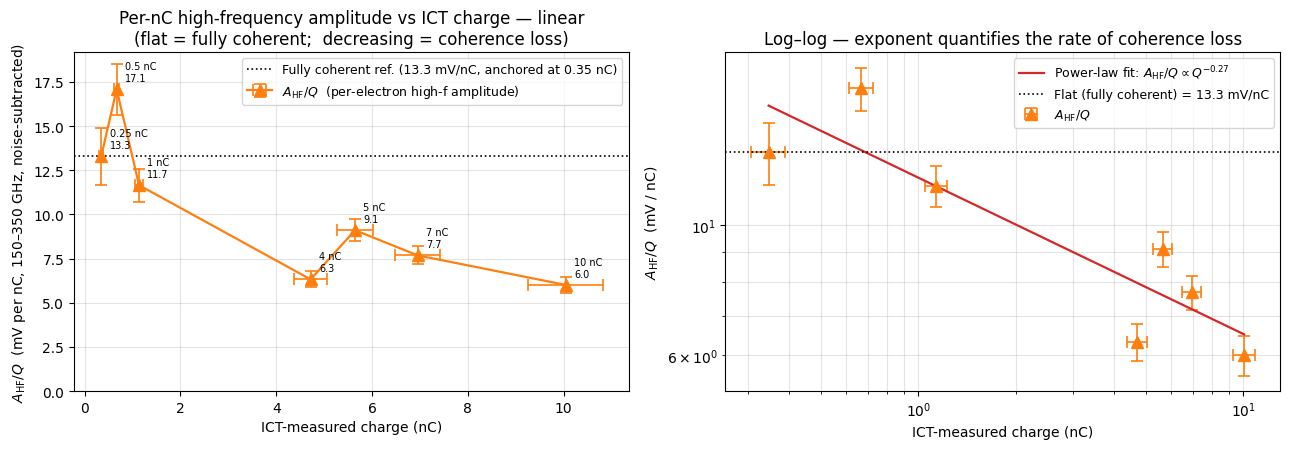

   Label    Q_ICT      A_HF     A_HF/Q    ± err
 0.25 nC    0.346     4.599      13.29     1.60
  0.5 nC    0.668    11.411      17.08     1.45
    1 nC    1.136    13.239      11.66     0.94
    4 nC    4.718    29.836       6.32     0.45
    5 nC    5.646    51.424       9.11     0.62
    7 nC    6.952    53.424       7.68     0.52
   10 nC   10.047    60.368       6.01     0.47

A_HF/Q ranges from 17.1 mV/nC (at 0.67 nC) → 6.0 mV/nC (at 10.05 nC)
Power-law in log-log:  A_HF/Q ∝ Q^-0.27   (exactly = slope_AHF − 1 = +0.73 − 1)
At 10 nC the per-electron high-f efficiency is 45% of the 0.35 nC value  → 55% coherence loss in the 150–350 GHz band.


In [23]:
# ── A_HF / Q (per-nC high-frequency amplitude) vs ICT charge ─────────────────
# Reuses Q_ict_arr, Q_ict_shot, AHF_arr from the previous cell.
# A coherent bunch radiates A_HF ∝ Q  →  A_HF/Q is constant with charge.
# A *decrease* in A_HF/Q with charge directly quantifies per-electron loss of
# high-f coherence due to space-charge bunch lengthening.

AHF_perQ = AHF_arr / Q_ict_arr                                  # mV / nC
# Error propagation: only the x (ICT charge) shot noise; AHF noise is captured
# in the noise-subtraction step in Section 4 and is small in this band.
AHF_perQ_err = AHF_perQ * (Q_ict_shot / Q_ict_arr)              # 1σ from ICT shot σ

# Reference: flat line at the lowest-charge value (fully coherent baseline)
ref_level = AHF_perQ[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

# (a) Linear
ax = axes[0]
ax.errorbar(Q_ict_arr, AHF_perQ, xerr=Q_ict_shot, yerr=AHF_perQ_err,
            fmt='C1^-', lw=1.6, ms=8, capsize=4, capthick=1.2, elinewidth=1.2,
            label=r'$A_{\rm HF}/Q$  (per-electron high-f amplitude)')
ax.axhline(ref_level, color='k', ls=':', lw=1.2,
           label=fr'Fully coherent ref. ({ref_level:.1f} mV/nC, anchored at {Q_ict_arr[0]:.2f} nC)')
for Q, A, lbl in zip(Q_ict_arr, AHF_perQ, [m['label'] for m in metrics]):
    ax.annotate(f'{lbl}\n{A:.1f}', (Q, A),
                textcoords='offset points', xytext=(6, 6), fontsize=7)
ax.set_xlabel('ICT-measured charge (nC)')
ax.set_ylabel(r'$A_{\rm HF}/Q$  (mV per nC, 150–350 GHz, noise-subtracted)')
ax.set_title('Per-nC high-frequency amplitude vs ICT charge — linear\n(flat = fully coherent;  decreasing = coherence loss)')
ax.legend(fontsize=9); ax.grid(True, alpha=0.35)
ax.set_ylim(bottom=0)

# (b) Log-log with power-law fit
slope_q, intercept_q = np.polyfit(np.log(Q_ict_arr), np.log(AHF_perQ), 1)
Q_fit_q   = np.linspace(Q_ict_arr.min(), Q_ict_arr.max(), 200)
AHF_perQ_fit = np.exp(intercept_q) * Q_fit_q**slope_q

ax = axes[1]
ax.errorbar(Q_ict_arr, AHF_perQ, xerr=Q_ict_shot, yerr=AHF_perQ_err,
            fmt='C1^', ms=8, capsize=4, capthick=1.2, elinewidth=1.2,
            label=r'$A_{\rm HF}/Q$')
ax.plot(Q_fit_q, AHF_perQ_fit, 'C3-', lw=1.6,
        label=fr'Power-law fit: $A_{{\rm HF}}/Q \propto Q^{{{slope_q:+.2f}}}$')
ax.axhline(ref_level, color='k', ls=':', lw=1.2,
           label=fr'Flat (fully coherent) = {ref_level:.1f} mV/nC')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('ICT-measured charge (nC)')
ax.set_ylabel(r'$A_{\rm HF}/Q$  (mV / nC)')
ax.set_title('Log–log — exponent quantifies the rate of coherence loss')
ax.legend(fontsize=9); ax.grid(True, alpha=0.35, which='both')

plt.tight_layout()
plt.savefig('Results/A_HF_perQ_vs_charge.png', dpi=200, bbox_inches='tight')
plt.show()

print(f"{'Label':>8}  {'Q_ICT':>7}  {'A_HF':>8}  {'A_HF/Q':>9}  {'± err':>7}")
for m, Qi, A, AperQ, e in zip(metrics, Q_ict_arr, AHF_arr, AHF_perQ, AHF_perQ_err):
    print(f"{m['label']:>8}  {Qi:7.3f}  {A:8.3f}  {AperQ:9.2f}  {e:7.2f}")

# Headline
print(f"\nA_HF/Q ranges from {AHF_perQ.max():.1f} mV/nC (at {Q_ict_arr[AHF_perQ.argmax()]:.2f} nC)"
      f" → {AHF_perQ.min():.1f} mV/nC (at {Q_ict_arr[AHF_perQ.argmin()]:.2f} nC)")
print(f"Power-law in log-log:  A_HF/Q ∝ Q^{slope_q:+.2f}   (exactly = slope_AHF − 1 = {slope:+.2f} − 1)")
print(f"At 10 nC the per-electron high-f efficiency is {100*AHF_perQ[-1]/ref_level:.0f}% of the 0.35 nC value"
      f"  → {100*(1-AHF_perQ[-1]/ref_level):.0f}% coherence loss in the 150–350 GHz band.")